In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
historyCall_path = './240826_data_dump/historyCalls.csv'
historyWorkflows_path = './240826_data_dump/historyWorkflows.csv'
historyLocations_path = './240826_data_dump/historyLocations.csv'

# Preprocessing historyCalls.csv

In [3]:
df_historyCall = pd.read_csv(historyCall_path, sep=';')
df_historyCall.head()

C:\Users\S_YZH\AppData\Local\Temp\ipykernel_18944\62896525.py:1: DtypeWarning: Columns (0: intercomConversationId, 1: intercomCallerNumber) have mixed types. Specify dtype option on import or set low_memory=False.
  df_historyCall = pd.read_csv(historyCall_path, sep=';')


,reasons,ward,clusterId,type,roomId,cancelPerson,intercomConversationId,personLocation,zone,clusterName,...,cancelTimestamp,wardId,priority,intercomCallerNumber,room,personName,cancellationTrigger,name,cancelLocation,triggeredBy
0,[],2V ZONE 2A,1032.0,Normal,71.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,NaN,Bed 2,...,2024-01-31T04:08:10Z,6.0,3,NaN,K 205,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 205,NaN
1,[],2V ZONE 2A,1126.0,Normal,89.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,NaN,Bed 2,...,2024-01-31T04:06:08Z,6.0,3,NaN,K 223,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 223,NaN
2,[],NaN,NaN,Care,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,NaN,2V ZONE 2A,ZONE 2A,NaN,...,2024-01-31T04:21:55.0721436Z,NaN,3,NaN,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,InputEvent,Draadloze oproep,2A_K 221,NaN
3,[],2V ZONE 2A,NaN,Normal,83.0,b49560dc6e0ffe0b7abc6a018ecde994d0c1b1e571464d...,NaN,NaN,NaN,NaN,...,2024-01-31T05:10:22Z,6.0,3,NaN,K 217,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 217,NaN
4,[],NaN,NaN,Care,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,NaN,2V ZONE 2B,ZONE 2B,NaN,...,2024-01-31T05:24:06.5463461Z,NaN,3,NaN,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,InputEvent,Draadloze oproep,2B_K 233,NaN


In [4]:
raw = df_historyCall['timestamp'].astype(str)

parsed = pd.to_datetime(raw, utc=True, errors='coerce')

df_historyCall['timestamp'] = pd.to_datetime(df_historyCall['timestamp'], utc=True, errors='coerce')

print("total rows:", len(df_historyCall))
print("bad timestamps:", parsed.isna().sum())

bad_rows_example = raw[parsed.isna()].value_counts().head(30)
print("\nbad timestamp values:")
print(bad_rows_example)



total rows: 37225
bad timestamps: 20724

bad timestamp values:
timestamp
2024-01-31T04:21:31.1096431Z    1
2024-01-31T05:20:51.1084997Z    1
2024-01-31T05:25:22.6230203Z    1
2024-01-31T05:57:08.4605595Z    1
2024-01-31T06:22:28.1753077Z    1
2024-01-31T06:23:53.3335565Z    1
2024-01-31T06:43:35.3071382Z    1
2024-01-31T06:51:07.0673340Z    1
2024-01-31T07:08:01.9450455Z    1
2024-01-31T08:14:10.1910598Z    1
2024-01-31T08:19:51.0794764Z    1
2024-01-31T08:22:34.4689202Z    1
2024-01-31T08:22:54.7623220Z    1
2024-01-31T08:59:32.5262603Z    1
2024-01-31T09:01:44.3295421Z    1
2024-01-31T09:08:32.2298477Z    1
2024-01-31T09:09:10.3744181Z    1
2024-01-31T09:15:49.5585242Z    1
2024-01-31T09:19:27.6820208Z    1
2024-01-31T09:20:17.6972753Z    1
2024-01-31T09:49:47.9622663Z    1
2024-01-31T09:51:02.2690004Z    1
2024-01-31T09:54:06.0304471Z    1
2024-01-31T09:58:51.3767006Z    1
2024-01-31T10:04:05.4074955Z    1
2024-01-31T10:30:54.1500328Z    1
2024-01-31T10:45:42.7920804Z    1
2024-01-3

In [5]:
col = "timestamp"
raw = df_historyCall[col]
parsed = pd.to_datetime(raw, utc=True, errors='coerce')
print("total rows:", len(df_historyCall))
print("bad timestamps:", parsed.isna().sum())

bad_raw = raw[parsed.isna()]
print("\nhow many bad row are na already")
print("bad_rows.isna().sum():", bad_raw.isna().sum())
print("\nbad timestamp values includes NA:")
print(bad_raw.head())

total rows: 37225
bad timestamps: 20724

how many bad row are na already
bad_rows.isna().sum(): 20724

bad timestamp values includes NA:
2    NaT
4    NaT
6    NaT
11   NaT
18   NaT
Name: timestamp, dtype: datetime64[us, UTC]


In [6]:
# check nan values
nan_summary = df_historyCall.isna().sum().sort_values(ascending=False)
nan_summary_percent = (nan_summary / len(df_historyCall) * 100).round(2).sort_values(ascending=False)
nan_summary_df = pd.DataFrame({
    'column': nan_summary.index,
    'nan_count': nan_summary.values,
    'nan_percent': nan_summary_percent.values
})

print("\nNaN Summary:")
print(nan_summary_df)


NaN Summary:
                    column  nan_count  nan_percent
0            justification      37225       100.00
1         annotationPerson      37225       100.00
2   intercomConversationId      37194        99.92
3     intercomCallerNumber      37194        99.92
4              clusterName      24932        66.98
5                clusterId      24932        66.98
6                   roomId      20751        55.74
7                     room      20751        55.74
8                timestamp      20724        55.67
9                     zone      16694        44.85
10                    area      16565        44.50
11          personLocation      15911        42.74
12              personType      15066        40.47
13                    ward       5962        16.02
14                  wardId       5962        16.02
15          cancelLocation        560         1.50
16         cancelTimestamp        405         1.09
17     cancellationTrigger        405         1.09
18             tr

In [7]:
# drop call columns
if "df_historyCall" not in globals():
    print("df_historyCall not found. Run the calls load cell first.")
else:
    miss_pct = df_historyCall.isna().mean()
    drop_cols = miss_pct[miss_pct > 0.7].index.tolist()
    if drop_cols:
        df_historyCall = df_historyCall.drop(columns=drop_cols)
        df_historyCall_cleaned = df_historyCall.copy()
        print(f"dropped {len(drop_cols)} columns (>70% missing): {drop_cols}")
    else:
        df_historyCall_cleaned = df_historyCall.copy()
        print("no columns exceeded 70% missing.")

dropped 4 columns (>70% missing): ['intercomConversationId', 'justification', 'annotationPerson', 'intercomCallerNumber']


In [8]:
# drop reasons ccolumn
if "df_historyCall_cleaned" in globals():
    if 'reasons' in df_historyCall_cleaned.columns:
        df_historyCall_cleaned = df_historyCall_cleaned.drop(columns=['reasons'])
        print("Dropped 'reasons' column.")
    else:
        print("'reasons' column not found in df_historyCall_cleaned.")
else:
    print("df_historyCall_cleaned not found. Run the cleanup cell first.")

Dropped 'reasons' column.


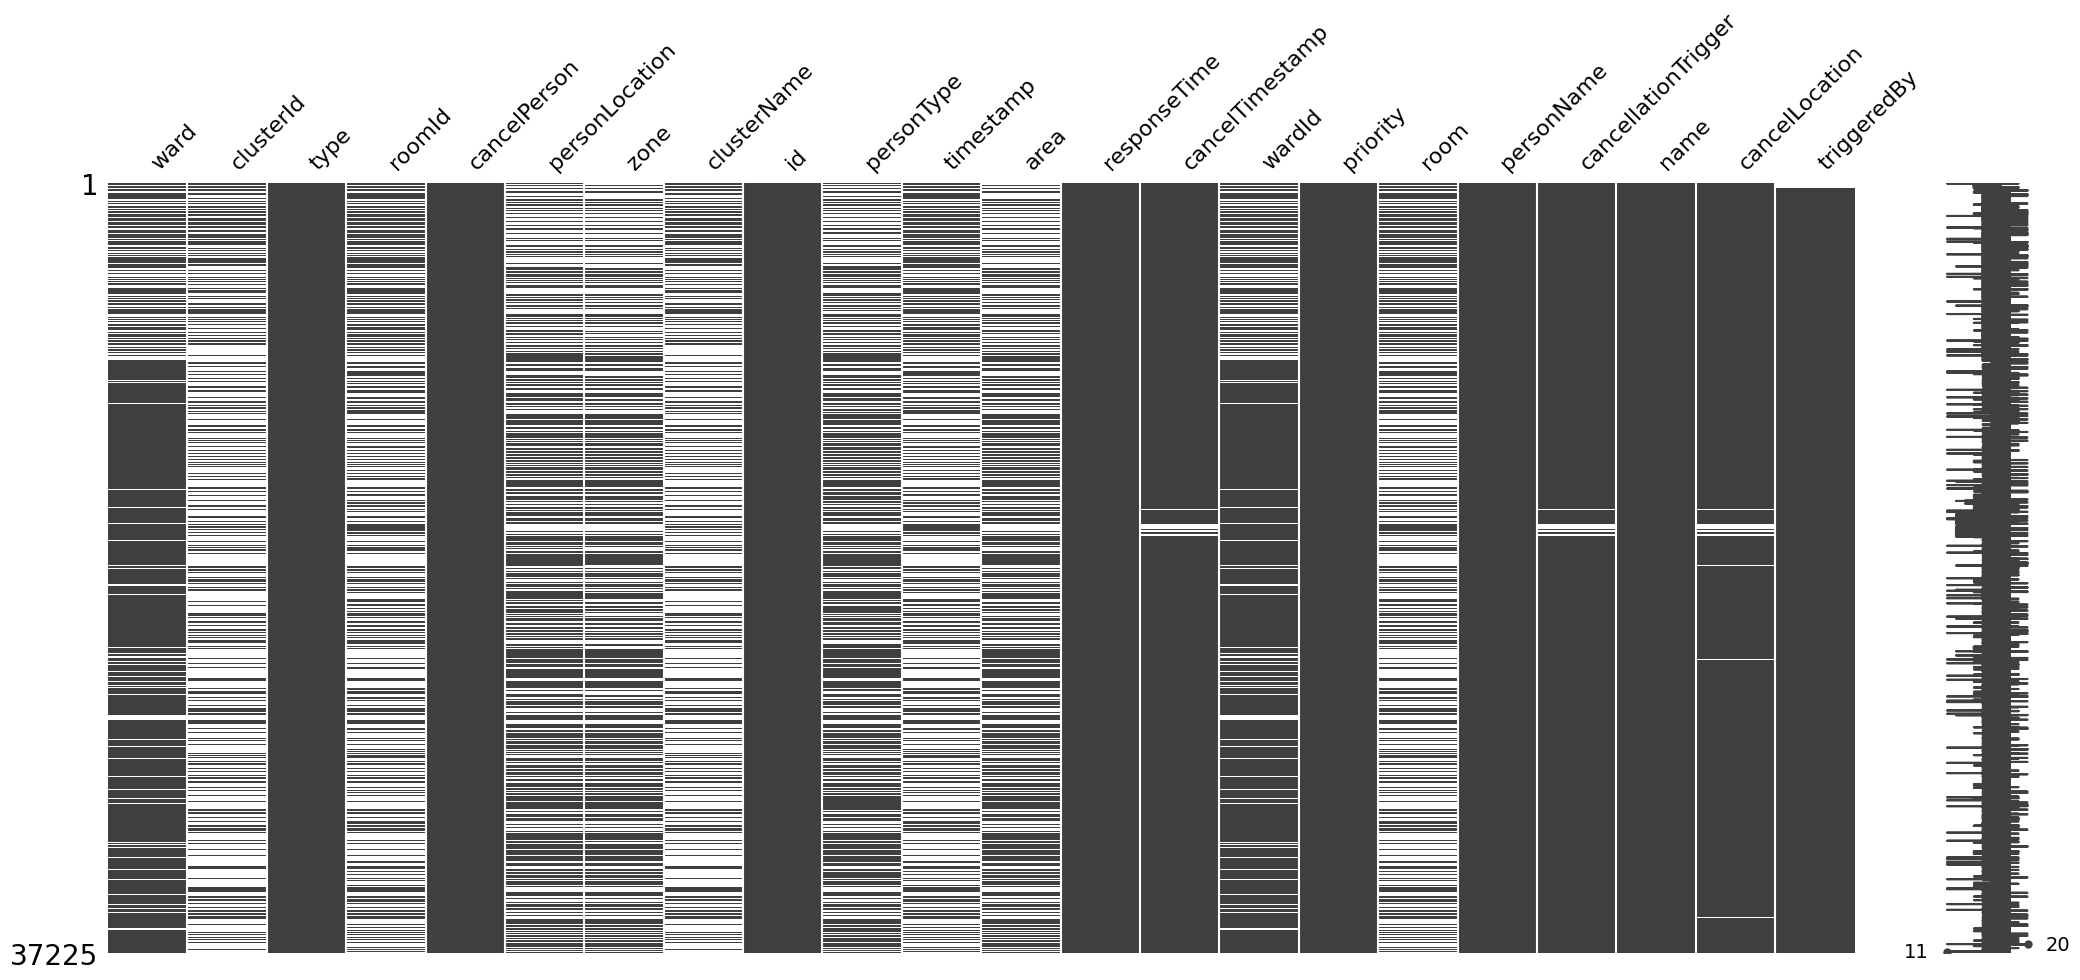

In [9]:
import missingno as msno

msno.matrix(df_historyCall_cleaned)
plt.show()

In [10]:
df_historyCall_cleaned.head()

,ward,clusterId,type,roomId,cancelPerson,personLocation,zone,clusterName,id,personType,...,responseTime,cancelTimestamp,wardId,priority,room,personName,cancellationTrigger,name,cancelLocation,triggeredBy
0,2V ZONE 2A,1032.0,Normal,71.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,Bed 2,72733,NaN,...,11360000000,2024-01-31T04:08:10Z,6.0,3,K 205,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 205,NaN
1,2V ZONE 2A,1126.0,Normal,89.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,Bed 2,72734,NaN,...,8610000000,2024-01-31T04:06:08Z,6.0,3,K 223,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 223,NaN
2,NaN,NaN,Care,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,2V ZONE 2A,ZONE 2A,NaN,72735,Patient,...,239625005,2024-01-31T04:21:55.0721436Z,NaN,3,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,InputEvent,Draadloze oproep,2A_K 221,NaN
3,2V ZONE 2A,NaN,Normal,83.0,b49560dc6e0ffe0b7abc6a018ecde994d0c1b1e571464d...,NaN,NaN,NaN,72736,NaN,...,7840000000,2024-01-31T05:10:22Z,6.0,3,K 217,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 217,NaN
4,NaN,NaN,Care,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,2V ZONE 2B,ZONE 2B,NaN,72737,Patient,...,1954378464,2024-01-31T05:24:06.5463461Z,NaN,3,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,InputEvent,Draadloze oproep,2B_K 233,NaN


In [11]:
# cleanup for historyCalls
if "df_historyCall" not in globals():
    print("df_historyCall not found. Run the calls load cell first.")
else:
    df_historyCall_cleaned = df_historyCall.copy()

    drop_cols = [
        "reasons",
        "intercomConversationId",
        "justification",
        "annotationPerson",
        "intercomCallerNumber",
    ]
    drop_existing = [c for c in drop_cols if c in df_historyCall_cleaned.columns]
    if drop_existing:
        df_historyCall_cleaned = df_historyCall_cleaned.drop(columns=drop_existing)
        print(f"dropped columns: {drop_existing}")

    time_cols = [c for c in ["timestamp", "cancelTimestamp"] if c in df_historyCall_cleaned.columns]
    for col in time_cols:
        df_historyCall_cleaned[col] = pd.to_datetime(df_historyCall_cleaned[col], utc=True, errors="coerce")

    invalid_cancel_count = 0
    if {"timestamp", "cancelTimestamp"}.issubset(df_historyCall_cleaned.columns):
        invalid_cancel = (
            df_historyCall_cleaned["timestamp"].notna()
            & df_historyCall_cleaned["cancelTimestamp"].notna()
            & (df_historyCall_cleaned["cancelTimestamp"] < df_historyCall_cleaned["timestamp"])
        )
        invalid_cancel_count = int(invalid_cancel.sum())
        if invalid_cancel_count:
            df_historyCall_cleaned.loc[invalid_cancel, "cancelTimestamp"] = pd.NaT

    before = len(df_historyCall_cleaned)
    if "id" in df_historyCall_cleaned.columns:
        df_historyCall_cleaned = df_historyCall_cleaned.drop_duplicates(subset=["id"], keep="first")
    else:
        df_historyCall_cleaned = df_historyCall_cleaned.drop_duplicates()
    dup_removed = before - len(df_historyCall_cleaned)

    missing_summary = df_historyCall_cleaned.isna().sum().sort_values(ascending=False)
    missing_percent = (missing_summary / len(df_historyCall_cleaned) * 100).round(2)

    non_datetime_cols = df_historyCall_cleaned.columns.difference(time_cols)
    df_historyCall_cleaned[non_datetime_cols] = df_historyCall_cleaned[non_datetime_cols].where(
        pd.notna(df_historyCall_cleaned[non_datetime_cols]),
        None
    )

    print(f"rows: {len(df_historyCall_cleaned):,}")
    print(f"duplicate rows removed: {dup_removed:,}")
    print(f"invalid cancelTimestamp fixed: {invalid_cancel_count:,}")
    print("\nmissing values (top 15):")
    display(
        pd.DataFrame({
            "missing": missing_summary.head(15),
            "missing_percent": missing_percent.head(15)
        })
    )

dropped columns: ['reasons']
rows: 37,225
duplicate rows removed: 0
invalid cancelTimestamp fixed: 0

missing values (top 15):


,missing,missing_percent
clusterId,24932,66.98
clusterName,24932,66.98
cancelTimestamp,21299,57.22
room,20751,55.74
roomId,20751,55.74
timestamp,20724,55.67
zone,16694,44.85
area,16565,44.50
personLocation,15911,42.74
personType,15066,40.47


In [12]:
df_historyCall_cleaned.head()

,ward,clusterId,type,roomId,cancelPerson,personLocation,zone,clusterName,id,personType,...,responseTime,cancelTimestamp,wardId,priority,room,personName,cancellationTrigger,name,cancelLocation,triggeredBy
0,2V ZONE 2A,1032.0,Normal,71.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,Bed 2,72733,NaN,...,11360000000,2024-01-31 04:08:10+00:00,6.0,3,K 205,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 205,NaN
1,2V ZONE 2A,1126.0,Normal,89.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,Bed 2,72734,NaN,...,8610000000,2024-01-31 04:06:08+00:00,6.0,3,K 223,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 223,NaN
2,NaN,NaN,Care,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,2V ZONE 2A,ZONE 2A,NaN,72735,Patient,...,239625005,NaT,NaN,3,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,InputEvent,Draadloze oproep,2A_K 221,NaN
3,2V ZONE 2A,NaN,Normal,83.0,b49560dc6e0ffe0b7abc6a018ecde994d0c1b1e571464d...,NaN,NaN,NaN,72736,NaN,...,7840000000,2024-01-31 05:10:22+00:00,6.0,3,K 217,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 217,NaN
4,NaN,NaN,Care,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,2V ZONE 2B,ZONE 2B,NaN,72737,Patient,...,1954378464,NaT,NaN,3,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,InputEvent,Draadloze oproep,2B_K 233,NaN


In [13]:
# for the column clusterId and clusterName, fill na with "unknown" and -1
if "df_historyCall_cleaned" in globals():
    for col in [ "clusterName"]:
        if col in df_historyCall_cleaned.columns:
            df_historyCall_cleaned[col] = df_historyCall_cleaned[col].fillna("unknown")
            print(f"filled NA in '{col}' with 'unknown'.")
        else:
            print(f"'{col}' column not found in df_historyCall_cleaned.")

df_historyCall_cleaned["clusterId"] = df_historyCall_cleaned["clusterId"].fillna(-1).astype("float64")


filled NA in 'clusterName' with 'unknown'.


In [14]:
# check datatypes of the cleaned dataframe
if "df_historyCall_cleaned" in globals():
    print("\nData types of df_historyCall_cleaned:")
    print(df_historyCall_cleaned.dtypes)
    


Data types of df_historyCall_cleaned:
ward                                   str
clusterId                          float64
type                                   str
roomId                             float64
cancelPerson                           str
personLocation                         str
zone                                   str
clusterName                            str
id                                   int64
personType                             str
timestamp              datetime64[us, UTC]
area                                   str
responseTime                           str
cancelTimestamp        datetime64[us, UTC]
wardId                             float64
priority                             int64
room                                   str
personName                             str
cancellationTrigger                    str
name                                   str
cancelLocation                         str
triggeredBy                            str
dtype: object


In [15]:
print(f"total nan in ward column: {df_historyCall_cleaned['ward'].isna().sum()}")
print(f"nan clusterId where ward is nan: {df_historyCall_cleaned[df_historyCall_cleaned['ward'].isna()]['clusterId'].isna().sum()}")
print(f"clusterId dtype: {df_historyCall_cleaned['clusterId'].dtype}")

df_historyCall_cleaned['clusterId'] = df_historyCall_cleaned['clusterId'].astype('object')

ward_nan_mask = df_historyCall_cleaned['ward'].isna()
df_historyCall_cleaned.loc[ward_nan_mask, 'clusterId'] = 'no value'

print(f"clusterId dtype: {df_historyCall_cleaned['clusterId'].dtype}")
print(f"records with ward=nan and clusterId='no value': {df_historyCall_cleaned[(df_historyCall_cleaned['ward'].isna()) & (df_historyCall_cleaned['clusterId'] == 'no value')].shape[0]}")
print("\nsample of records with ward=nan:")
print(df_historyCall_cleaned[df_historyCall_cleaned['ward'].isna()][['ward', 'clusterId', 'personLocation', 'type']].head(10))

total nan in ward column: 5962
nan clusterId where ward is nan: 0
clusterId dtype: float64
clusterId dtype: object
records with ward=nan and clusterId='no value': 5962

sample of records with ward=nan:
   ward clusterId personLocation    type
2   NaN  no value     2V ZONE 2A    Care
4   NaN  no value     2V ZONE 2B    Care
6   NaN  no value     2V ZONE 2A    Care
11  NaN  no value     2V ZONE 2A    Care
18  NaN  no value     2V ZONE 2A    Care
19  NaN  no value     1V ZONE 1A    Care
21  NaN  no value            NaN  Normal
25  NaN  no value     2V ZONE 2B    Care
26  NaN  no value     1V ZONE 1A    Care
28  NaN  no value     1V ZONE 1B    Care


In [17]:
# current state before filling
print("befer filling:")
print(f"total nan in ward column: {df_historyCall_cleaned['ward'].isna().sum()}")
print(f"nan in ward where type='Care': {df_historyCall_cleaned[(df_historyCall_cleaned['type'] == 'Care') & (df_historyCall_cleaned['ward'].isna())].shape[0]}")

mask = (df_historyCall_cleaned['type'] == 'Care') & (df_historyCall_cleaned['ward'].isna())
df_historyCall_cleaned.loc[mask, 'ward'] = df_historyCall_cleaned.loc[mask, 'personLocation']

# state after filling
print("\nafter filling:")
print(f"total nan in ward column: {df_historyCall_cleaned['ward'].isna().sum()}")
print(f"nan in ward where type='Care': {df_historyCall_cleaned[(df_historyCall_cleaned['type'] == 'Care') & (df_historyCall_cleaned['ward'].isna())].shape[0]}")


befer filling:
total nan in ward column: 757
nan in ward where type='Care': 0

after filling:
total nan in ward column: 757
nan in ward where type='Care': 0


In [18]:
missing_summary = df_historyCall_cleaned.isna().sum().sort_values(ascending=False)
missing_percent = (missing_summary / len(df_historyCall_cleaned) * 100).round(2)
print("\nmissing values (top 15):")
display(
    pd.DataFrame({
        "missing": missing_summary.head(15),
        "missing_percent": missing_percent.head(15)
    })
)




missing values (top 15):


,missing,missing_percent
cancelTimestamp,21299,57.22
roomId,20751,55.74
room,20751,55.74
timestamp,20724,55.67
zone,16694,44.85
area,16565,44.50
personLocation,15911,42.74
personType,15066,40.47
wardId,5962,16.02
ward,757,2.03


## Explaination of the plot

- **left bar chart:** what kind of calls happen most? it shows class balance for call categories, so i can quickly see dominant vs rare call types.

- **middle bar plot:** it shows how urgent are calls overall, it gives the workload mix by urgency level and heps verify if the data is skewed toward low/high priority

- **right heatmap plot:** how do category and urgency interact? this plot shows combination (for example type that is disproportionately high priority) that single variable charts cannot show

these 3 plots actually show progress from single variable to multi variable which is actually the minimum solid exploratory Data Analysis pattern before work on model

> these also detect class imbalance, which inportant for sampling, weighting and metric choice.
> it also guide feature design, for example interaction features like `type_priority` patterns
> these plots also informs operation which call types, priority mixes drive load
> it also provide a baseline to compare future periods for drift or anomaly checks


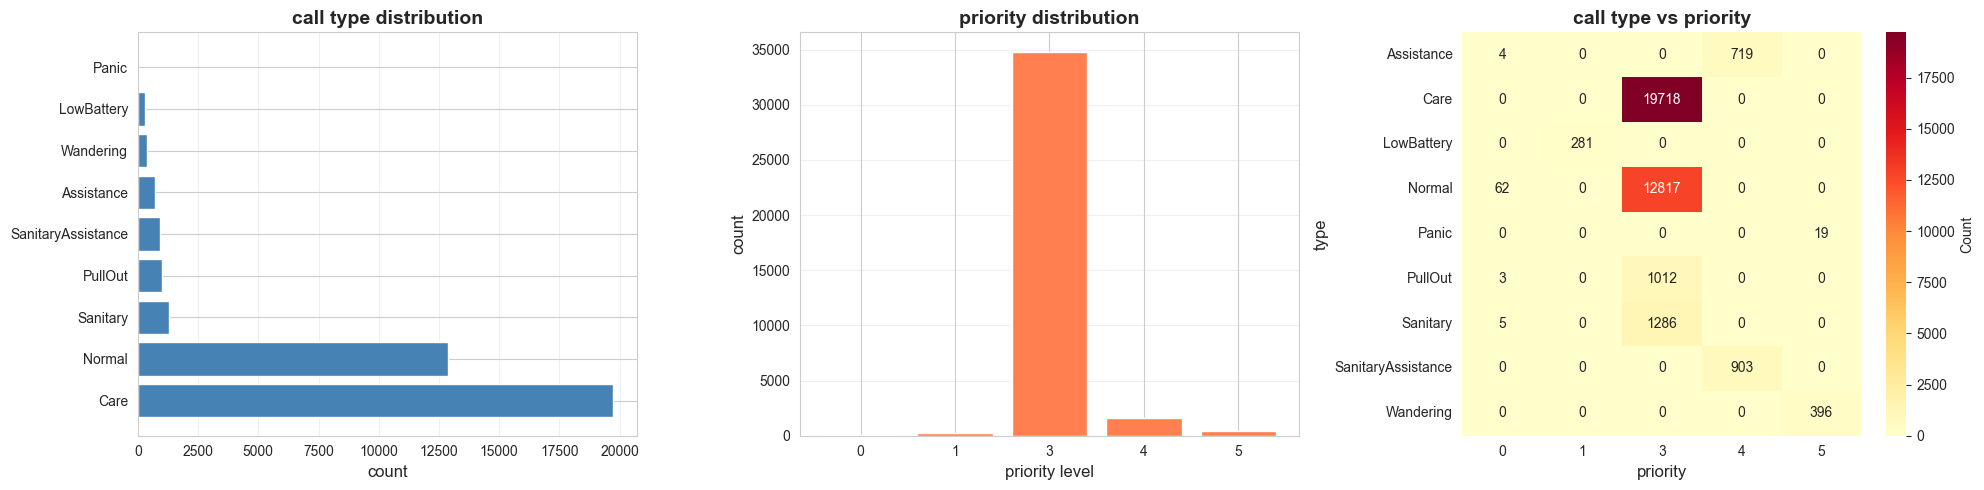

call types:
   - total calls: 37,225
   - most common type: Care (19,718 calls)
   - least common type: Panic (19 calls)


In [19]:
sns.set_style("whitegrid")
sns.set_palette("husl")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# type counts
type_counts = df_historyCall_cleaned['type'].value_counts()
axes[0].barh(type_counts.index, type_counts.values, color='steelblue')
axes[0].set_xlabel('count', fontsize=12)
axes[0].set_title('call type distribution', fontsize=14, fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)

# priority distribution
priority_counts = df_historyCall_cleaned['priority'].value_counts().sort_index()
axes[1].bar(priority_counts.index.astype(str), priority_counts.values, color='coral')
axes[1].set_xlabel('priority level', fontsize=12)
axes[1].set_ylabel('count', fontsize=12)
axes[1].set_title('priority distribution', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

# Type by Priority heatmap
type_priority = pd.crosstab(df_historyCall_cleaned['type'], df_historyCall_cleaned['priority'])
sns.heatmap(type_priority, annot=True, fmt='d', cmap='YlOrRd', ax=axes[2], cbar_kws={'label': 'Count'})
axes[2].set_title('call type vs priority', fontsize=14, fontweight='bold')
axes[2].set_xlabel('priority', fontsize=12)
axes[2].set_ylabel('type', fontsize=12)

plt.tight_layout()
plt.show()

print("call types:")
print(f"   - total calls: {len(df_historyCall_cleaned):,}")
print(f"   - most common type: {type_counts.index[0]} ({type_counts.values[0]:,} calls)")
print(f"   - least common type: {type_counts.index[-1]} ({type_counts.values[-1]:,} calls)")

In [30]:
# extract time features
df_historyCall_cleaned['hour'] = df_historyCall_cleaned['timestamp'].dt.hour
df_historyCall_cleaned['dayofweek'] = df_historyCall_cleaned['timestamp'].dt.dayofweek
df_historyCall_cleaned['date'] = df_historyCall_cleaned['timestamp'].dt.date

hourly_calls = df_historyCall_cleaned['hour'].value_counts().sort_index()

dow_names = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']
dow_calls = df_historyCall_cleaned['dayofweek'].value_counts().sort_index()

hour_dow_pivot = df_historyCall_cleaned.groupby(['dayofweek', 'hour']).size().unstack(fill_value=0)


hour_type = df_historyCall_cleaned.groupby(['hour', 'type']).size().unstack(fill_value=0)

## Explaination of the plot
- hourly call distribution plot: this plot shows with in 24 hours demand pattern and peak hours, later could staffing by hour, to defin peak time create time features for forecasting or anomaly model
- for the calls by day of the week plot shows weekly calls numberon each day, later should refer to shift planning by a day and weekly seasonality features like dayofwork or weekend flag, which is better workload prediction
- for the plot of day vs hour heatmap, which combine both dimensions to find when pressure happens, which also help detect unusual spikes vs normal day hour baseline
- for the plot of call types within day, this one shows mix of call types changes through the day not just total volume, and later for right person on right time kind schedule will help alot

1. with analysis of these part, it could help with prompt grouding, which instead asking llm on raw event but pass true fact, it could help a lot with hallucination
2. this `hour`, `dayofork`, `hour+type`, peak and off peak flag are strong features for later forcasting call, triage suggestions and anomaly detection
3. the heatmap this engineering could help when trigger rules lie thrusday 5am is 2x normal, and llm could generate human readable alert explaination and recommandation


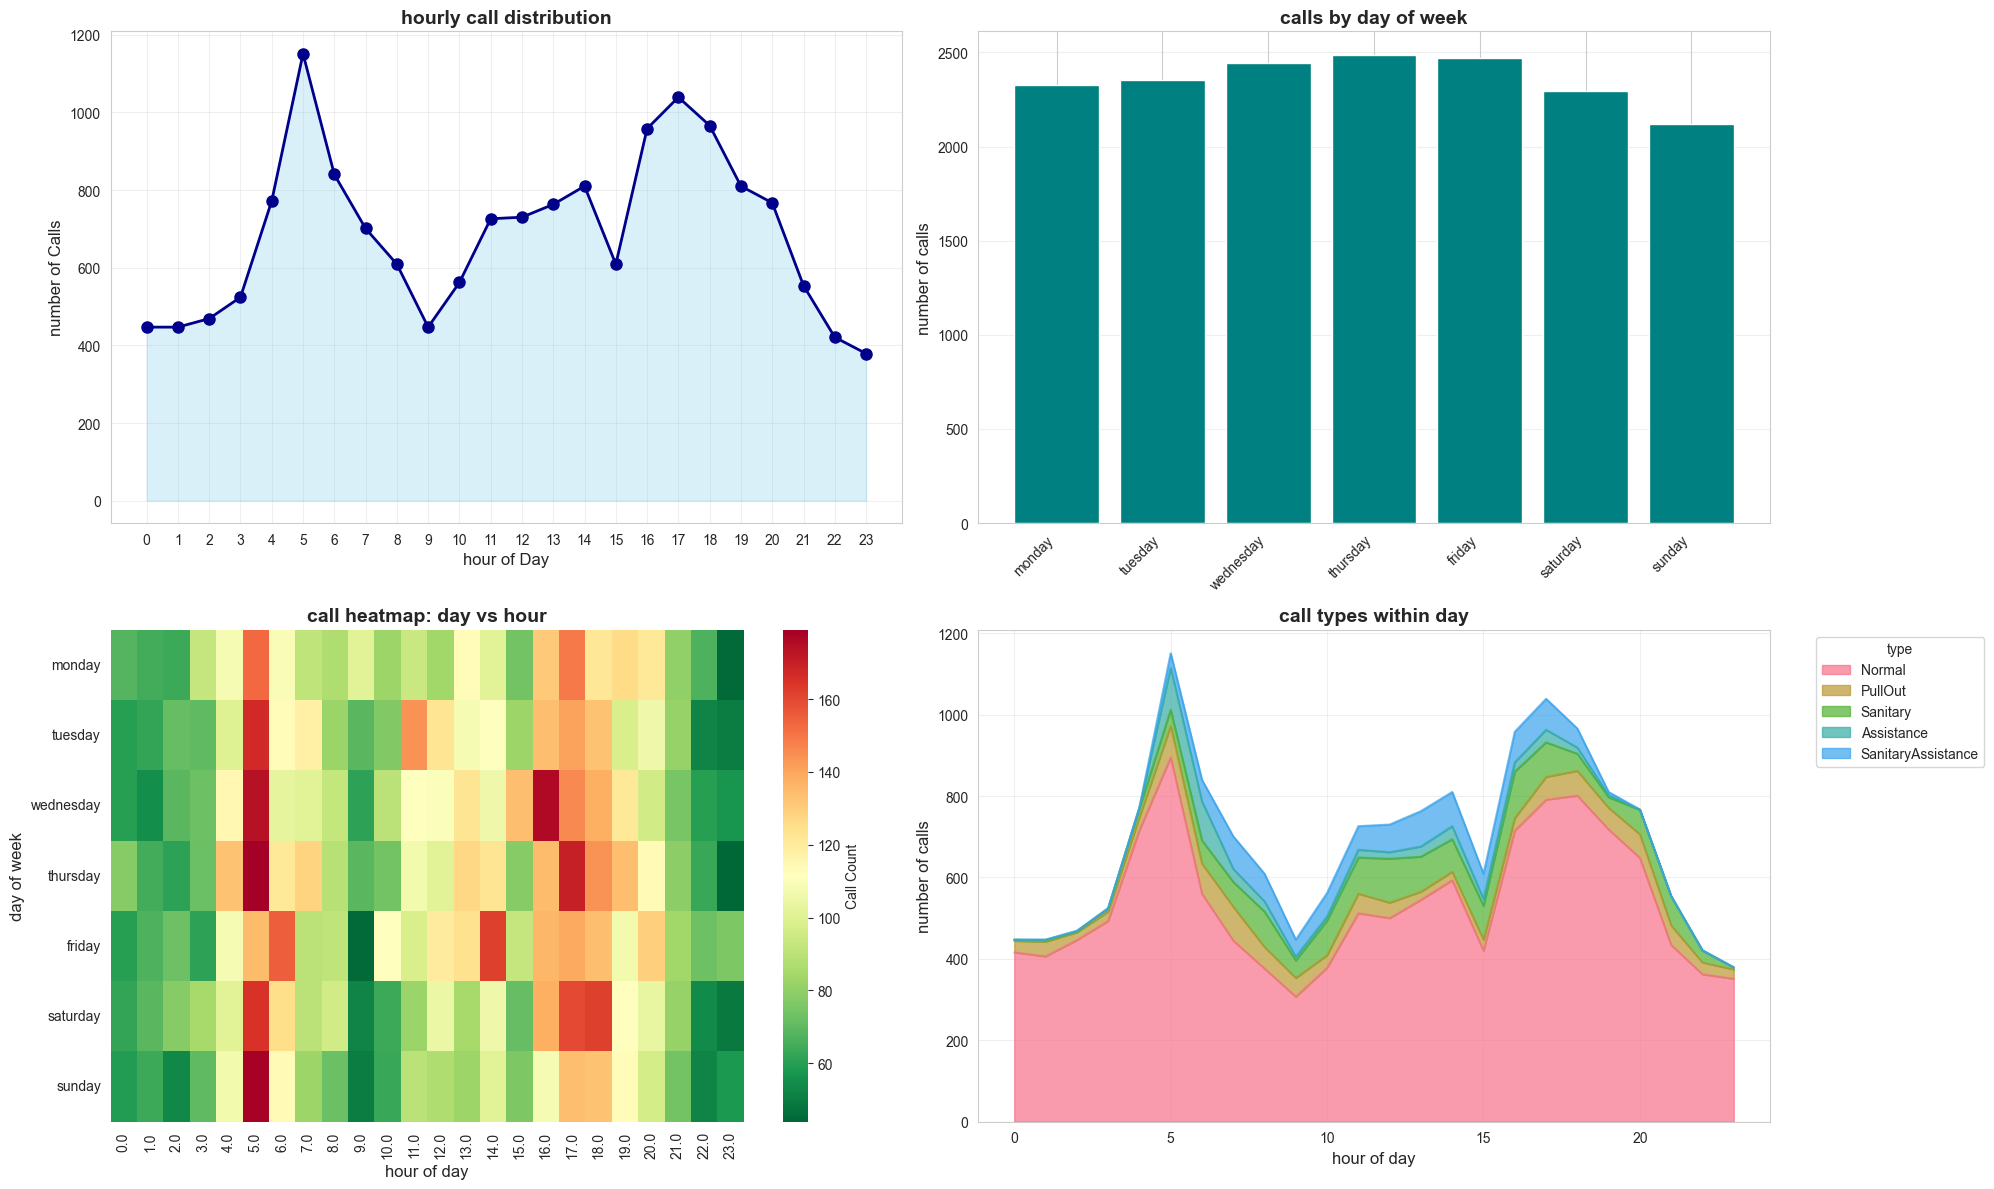


temporal insights:
   - peak hour: 5:00 (1151 calls)
   - quietest hour: 23.0:00 (379 calls)
   - busiest day: thursday (2488 calls)


In [31]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

# hourly distribution
axes[0, 0].plot(hourly_calls.index, hourly_calls.values, marker='o', linewidth=2, markersize=8, color='darkblue')
axes[0, 0].fill_between(hourly_calls.index, hourly_calls.values, alpha=0.3, color='skyblue')
axes[0, 0].set_xlabel('hour of Day', fontsize=12)
axes[0, 0].set_ylabel('number of Calls', fontsize=12)
axes[0, 0].set_title('hourly call distribution', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xticks(range(0, 24))

# week distribution
axes[0, 1].bar(dow_calls.index, dow_calls.values, color='teal')
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(dow_names, rotation=45, ha='right')
axes[0, 1].set_ylabel('number of calls', fontsize=12)
axes[0, 1].set_title('calls by day of week', fontsize=14, fontweight='bold')
axes[0, 1].grid(axis='y', alpha=0.3)

# hour vs day of week
sns.heatmap(hour_dow_pivot, cmap='RdYlGn_r', annot=False, fmt='d', ax=axes[1, 0], cbar_kws={'label': 'Call Count'})
axes[1, 0].set_yticklabels(dow_names, rotation=0)
axes[1, 0].set_xlabel('hour of day', fontsize=12)
axes[1, 0].set_ylabel('day of week', fontsize=12)
axes[1, 0].set_title('call heatmap: day vs hour', fontsize=14, fontweight='bold')

# call type over hours
hour_type.plot(kind='area', stacked=True, ax=axes[1, 1], alpha=0.7)
axes[1, 1].set_xlabel('hour of day', fontsize=12)
axes[1, 1].set_ylabel('number of calls', fontsize=12)
axes[1, 1].set_title('call types within day', fontsize=14, fontweight='bold')
axes[1, 1].legend(title='type', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# peak hours convert to int to avoid float64 indexing error
peak_hour = int(hourly_calls.idxmax())
busiest_day_idx = int(dow_calls.idxmax())
print(f"\ntemporal insights:")
print(f"   - peak hour: {peak_hour}:00 ({hourly_calls.max()} calls)")
print(f"   - quietest hour: {hourly_calls.idxmin()}:00 ({hourly_calls.min()} calls)")
print(f"   - busiest day: {dow_names[busiest_day_idx]} ({dow_calls.max()} calls)")

## Explaination of plot below
- plot top 15 wards by call volume shows where workload is concertrated, it could give ranked hotspot so the model can prioritize summarise, recommendation and also escalation focus base on ward
- for the plot call type mix by top 10 wards, it shows each ward composition not just total volume, which enable ward specific reasoning like ward a is normal heacy ward b is more sanitory assistance so advice is tailored rather than generic
- for the plot of person type distribution by ward, it links demand to user group, which help generate operational actions ike training workflow updates, data quality check with clearer audience targeting
- the plot ward vs priprity heatmap shows distribution per ward, which support risk risk aware prompt and alert and explanable triage narratives


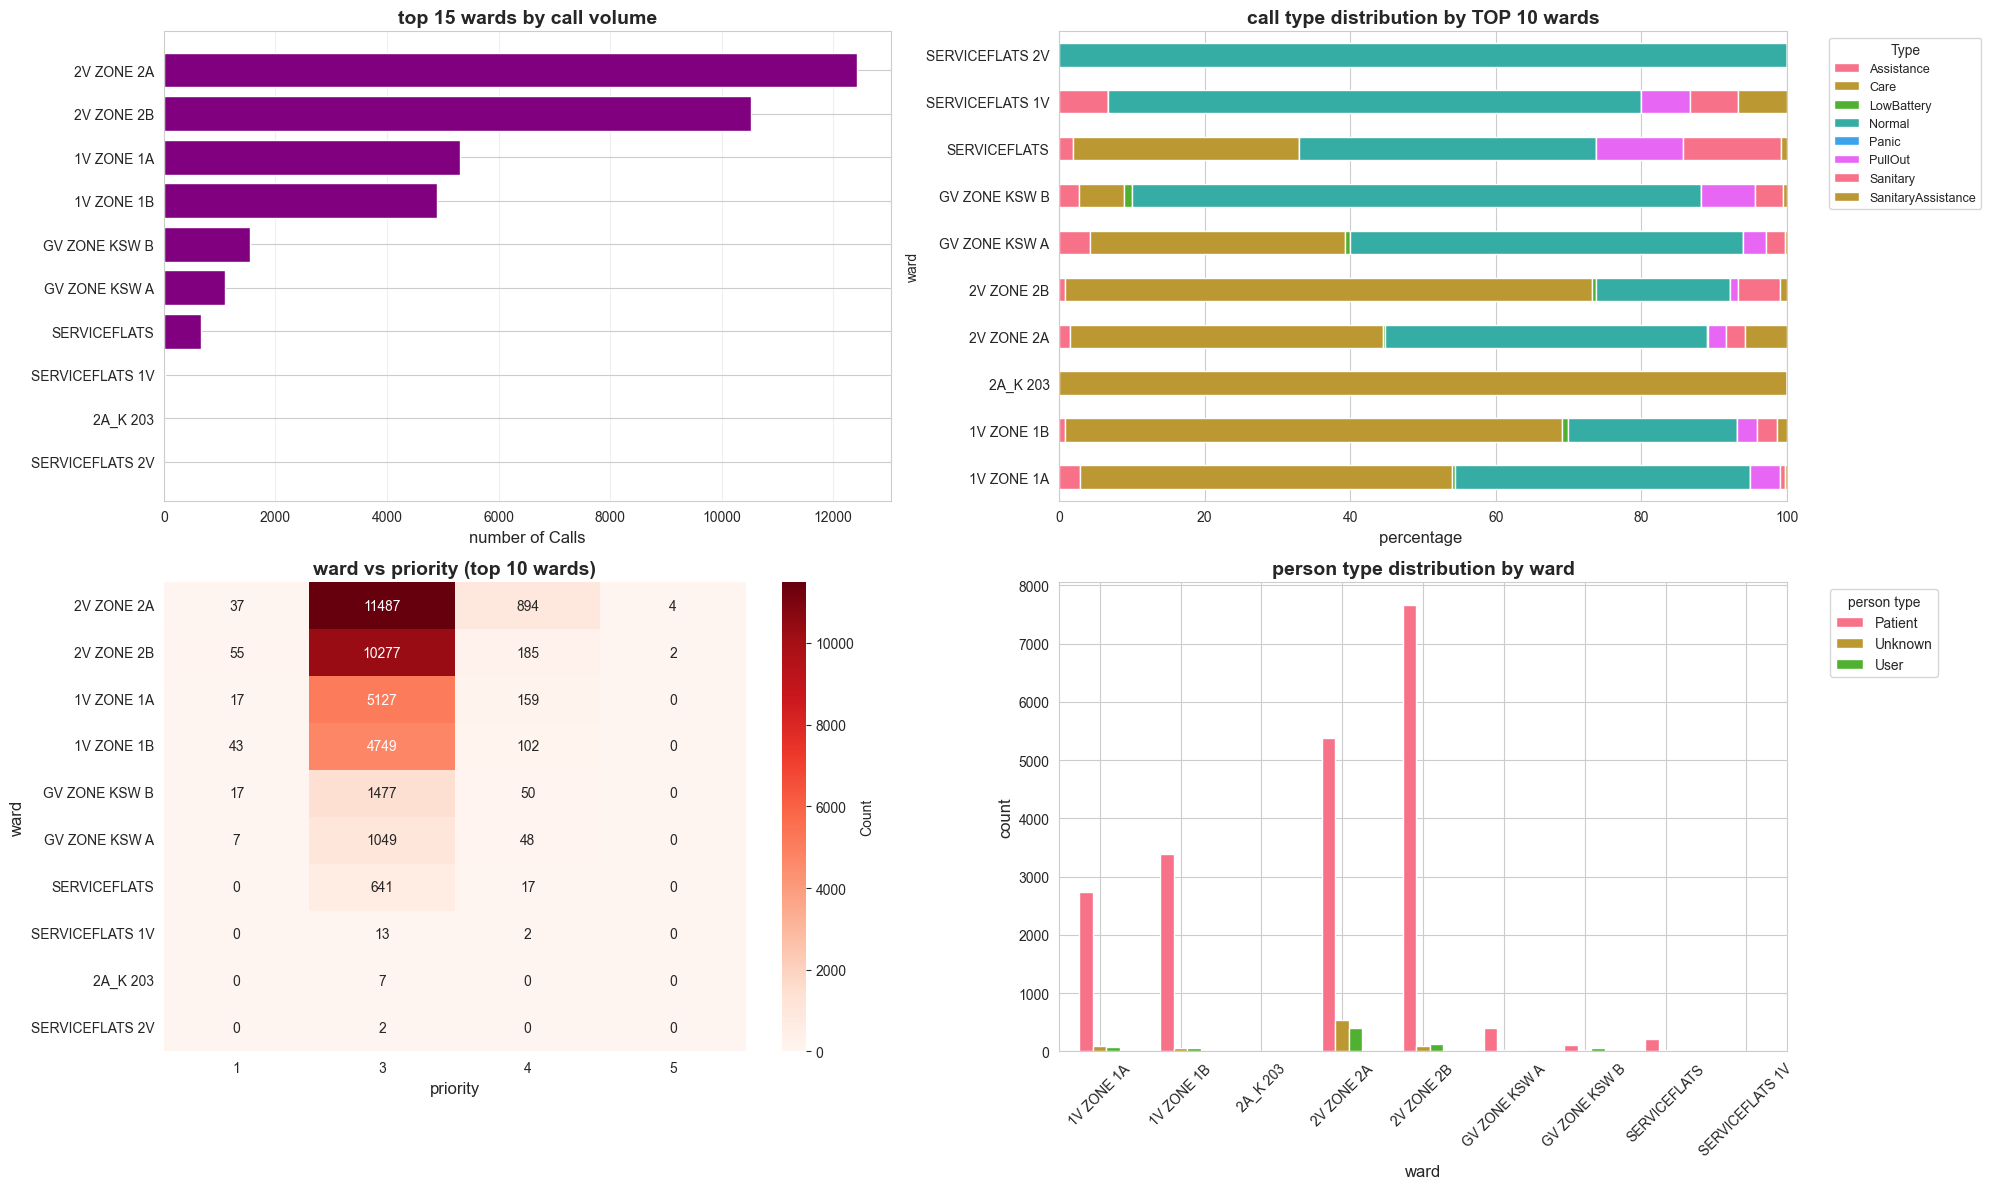


ward insights:
   - total unique wards: 10
   - busiest ward: 2V ZONE 2A (12,422 calls)
   - top 3 wards account for 75.9% of all calls


In [32]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

# top 15 wards by call volume
ward_counts = df_historyCall_cleaned['ward'].value_counts().head(15)
axes[0, 0].barh(range(len(ward_counts)), ward_counts.values, color='purple')
axes[0, 0].set_yticks(range(len(ward_counts)))
axes[0, 0].set_yticklabels(ward_counts.index)
axes[0, 0].set_xlabel('number of Calls', fontsize=12)
axes[0, 0].set_title('top 15 wards by call volume', fontsize=14, fontweight='bold')
axes[0, 0].grid(axis='x', alpha=0.3)
axes[0, 0].invert_yaxis()

# ward vs call type (top 10)
top_wards = df_historyCall_cleaned['ward'].value_counts().head(10).index
ward_type_data = df_historyCall_cleaned[df_historyCall_cleaned['ward'].isin(top_wards)]
ward_type_ct = pd.crosstab(ward_type_data['ward'], ward_type_data['type'])
ward_type_ct_pct = ward_type_ct.div(ward_type_ct.sum(axis=1), axis=0) * 100
ward_type_ct_pct.plot(kind='barh', stacked=True, ax=axes[0, 1])
axes[0, 1].set_xlabel('percentage ', fontsize=12)
axes[0, 1].set_title('call type distribution by TOP 10 wards', fontsize=14, fontweight='bold')
axes[0, 1].legend(title='Type', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)

# ward vs priority heatmap
ward_priority = pd.crosstab(df_historyCall_cleaned['ward'], df_historyCall_cleaned['priority'])
top_ward_priority = ward_priority.loc[ward_counts.head(10).index]
sns.heatmap(top_ward_priority, annot=True, fmt='d', cmap='Reds', ax=axes[1, 0], cbar_kws={'label': 'Count'})
axes[1, 0].set_title('ward vs priority (top 10 wards)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('priority', fontsize=12)
axes[1, 0].set_ylabel('ward', fontsize=12)

# person type by ward
ward_person_data = df_historyCall_cleaned[df_historyCall_cleaned['ward'].isin(top_wards)]
ward_person_ct = pd.crosstab(ward_person_data['ward'], ward_person_data['personType'])
ward_person_ct.plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_xlabel('ward', fontsize=12)
axes[1, 1].set_ylabel('count', fontsize=12)
axes[1, 1].set_title('person type distribution by ward', fontsize=14, fontweight='bold')
axes[1, 1].legend(title='person type', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(f"\nward insights:")
print(f"   - total unique wards: {df_historyCall_cleaned['ward'].nunique()}")
print(f"   - busiest ward: {ward_counts.index[0]} ({ward_counts.values[0]:,} calls)")
print(f"   - top 3 wards account for {ward_counts.head(3).sum() / len(df_historyCall_cleaned) * 100:.1f}% of all calls")

## Explain plot below

- **Histogram:** shows how `responseTime` is distributed. Most calls are fast (left side), with a long right tail of very slow cases; red dashed line is the **median**. it could build better features for prediction or routing type, priority, ward and historical median response time

- **Boxplot by `type`:** compares response-time spread for each call type. Middle line = median, box = typical range, dots = outliers. Useful to see which types are unstable or consistently slow. this one help to create anomaly alerts which is like for example why this call is likely delayed when currect context matches slow atterns

- **Bars by `priority`:** compares **mean vs median** per priority. If mean >> median, that priority has heavy outliers (a few very slow calls pulling average up). this plot help to understand and generate operational summy automatic which for example ward x and call type y are main deplay contributor this week

- **Avg by ward:** ranks wards by average response time (top-10 wards by volume). Quickly identifies where operations are slower. thsi plot helps to support triage recommendations which llm can suggest escalation when high ris combination have long tails

**Mean vs Median**
- `mean` = sensitive to extreme outliers.
- `median` = middle value, robust to outliers.
- In your plots, big gaps between mean and median suggest skewed data and extreme delays.

**One critical caveat**
- on the y/x scales show values near `1e10–1e11` seconds, which is likely a unit/parsing issue here, should fix it later
- to fix units first before making business decisions.


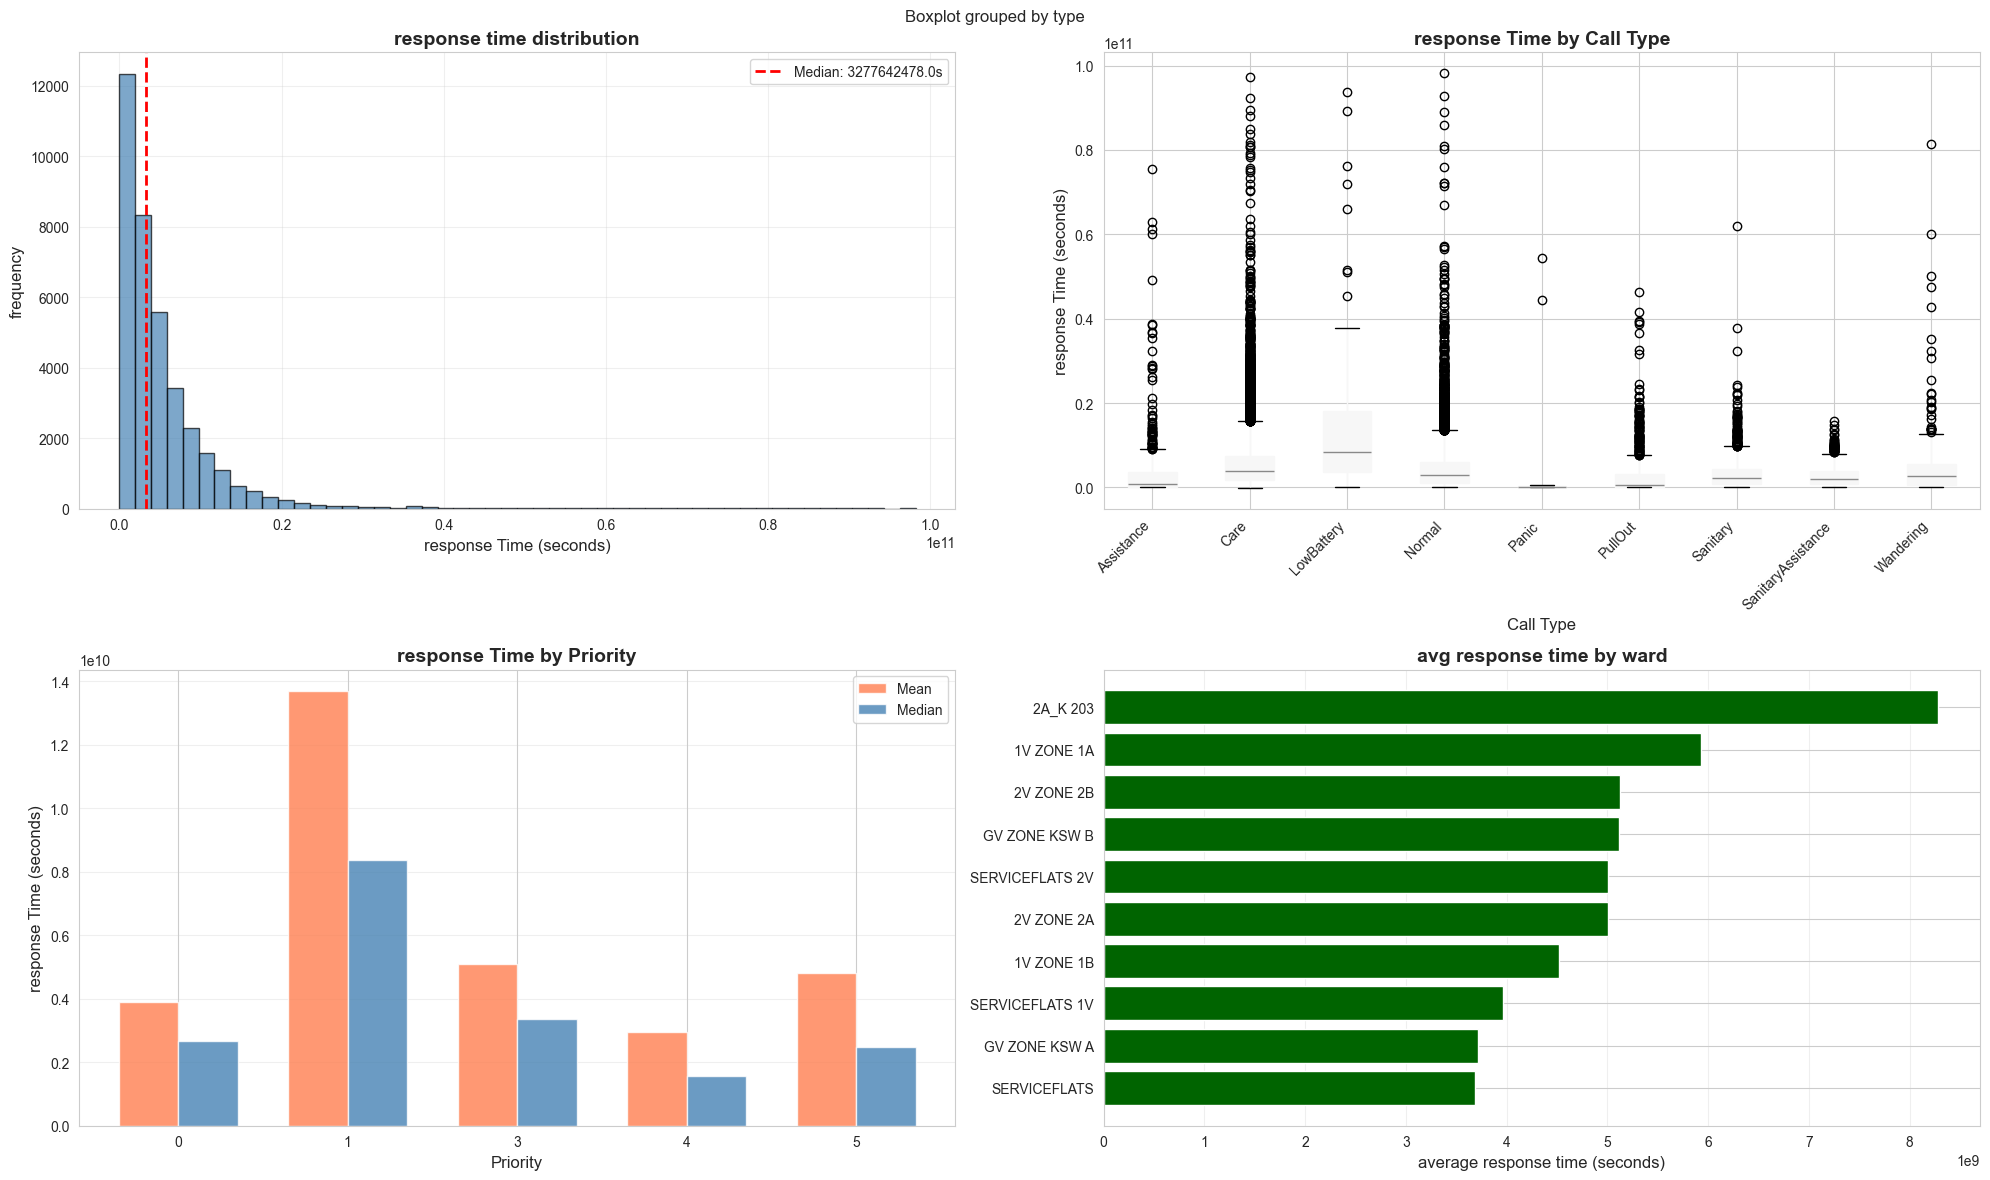


response time insights:
   - average response time: 5065378183.0 seconds
   - median response time: 3277642478.0 seconds
   - fastest avg by type: PullOut
   - slowest avg by type: LowBattery


In [35]:
if 'responseTime' in df_historyCall_cleaned.columns:
    # here convert responseTime to numeric
    df_historyCall_cleaned['responseTime'] = pd.to_numeric(df_historyCall_cleaned['responseTime'], errors='coerce')
    
    response_data = df_historyCall_cleaned[df_historyCall_cleaned['responseTime'].notna()].copy()
    
    if len(response_data) > 0:
        fig, axes = plt.subplots(2, 2, figsize=(20, 12))
        
        # response time distribution
        axes[0, 0].hist(response_data['responseTime'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
        axes[0, 0].axvline(response_data['responseTime'].median(), color='red', linestyle='--', linewidth=2, label=f'Median: {response_data["responseTime"].median():.1f}s')
        axes[0, 0].set_xlabel('response Time (seconds)', fontsize=12)
        axes[0, 0].set_ylabel('frequency', fontsize=12)
        axes[0, 0].set_title('response time distribution', fontsize=14, fontweight='bold')
        axes[0, 0].legend()
        axes[0, 0].grid(alpha=0.3)
        
        # response time by call type (boxplot)
        response_data.boxplot(column='responseTime', by='type', ax=axes[0, 1], patch_artist=True)
        axes[0, 1].set_xlabel('Call Type', fontsize=12)
        axes[0, 1].set_ylabel('response Time (seconds)', fontsize=12)
        axes[0, 1].set_title('response Time by Call Type', fontsize=14, fontweight='bold')
        axes[0, 1].tick_params(axis='x', rotation=45)
        plt.sca(axes[0, 1])
        plt.xticks(rotation=45, ha='right')
        
        # response time by priority
        priority_response = response_data.groupby('priority')['responseTime'].agg(['mean', 'median', 'std']).reset_index()
        x = np.arange(len(priority_response))
        width = 0.35
        axes[1, 0].bar(x - width/2, priority_response['mean'], width, label='Mean', color='coral', alpha=0.8)
        axes[1, 0].bar(x + width/2, priority_response['median'], width, label='Median', color='steelblue', alpha=0.8)
        axes[1, 0].set_xlabel('Priority', fontsize=12)
        axes[1, 0].set_ylabel('response Time (seconds)', fontsize=12)
        axes[1, 0].set_title('response Time by Priority', fontsize=14, fontweight='bold')
        axes[1, 0].set_xticks(x)
        axes[1, 0].set_xticklabels(priority_response['priority'])
        axes[1, 0].legend()
        axes[1, 0].grid(axis='y', alpha=0.3)
        
        # Response time by top wards
        top_wards_response = response_data[response_data['ward'].isin(ward_counts.head(10).index)]
        ward_response_avg = top_wards_response.groupby('ward')['responseTime'].mean().sort_values(ascending=True)
        axes[1, 1].barh(range(len(ward_response_avg)), ward_response_avg.values, color='darkgreen')
        axes[1, 1].set_yticks(range(len(ward_response_avg)))
        axes[1, 1].set_yticklabels(ward_response_avg.index)
        axes[1, 1].set_xlabel('average response time (seconds)', fontsize=12)
        axes[1, 1].set_title('avg response time by ward', fontsize=14, fontweight='bold')
        axes[1, 1].grid(axis='x', alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        print(f"\nresponse time insights:")
        print(f"   - average response time: {response_data['responseTime'].mean():.1f} seconds")
        print(f"   - median response time: {response_data['responseTime'].median():.1f} seconds")
        print(f"   - fastest avg by type: {response_data.groupby('type')['responseTime'].mean().idxmin()}")
        print(f"   - slowest avg by type: {response_data.groupby('type')['responseTime'].mean().idxmax()}")
    else:
        print("No valid response time data available")
else:
    print("Response time column not found in dataset")

## Explaination of below plot
- **top 10 cancellation triggers:** which trigger reasons happen most often. in this chart, `InputEvent` and `NfcBadge` dominate, so cancellations are mostly user/device interaction driven. this 

- **trigger by call type, stacked:** this plot for each trigger, which call types contribute to it. this also shows whether a trigger is general across all types or focus on specific workflows. this one help with snomaly alert, if trigger or location suddenly spike above baseline

- **top 15 cancel locations:** this plot shows where cancellations happen most. this one good for spotting location hotspots (for example process, hardware, or training issues by area).

- **top 15 cancel people:** who cancels most often. Useful for workload pattern checks, but if values are IDs/hashes, interpret as actors/sources, not necessarily individuals.


**how this prepared for later**
- Build structured features: `cancellationTrigger`, `type`, `cancelLocation`, `cancelPerson`.
- Generate explainable summaries: “Most cancellations are `InputEvent` in wards X/Y, mainly in type Z.”
- Support anomaly alerts: if a trigger/location suddenly spikes above baseline.
- Improve triage recommendations: LLM can propose targeted actions (device check, workflow review, staff coaching) based on dominant cancellation pattern.

- if `cancelPerson` is highly skewed (one actor much higher), validate whether it is a shared terminal/system account before concluding person-specific behavior.

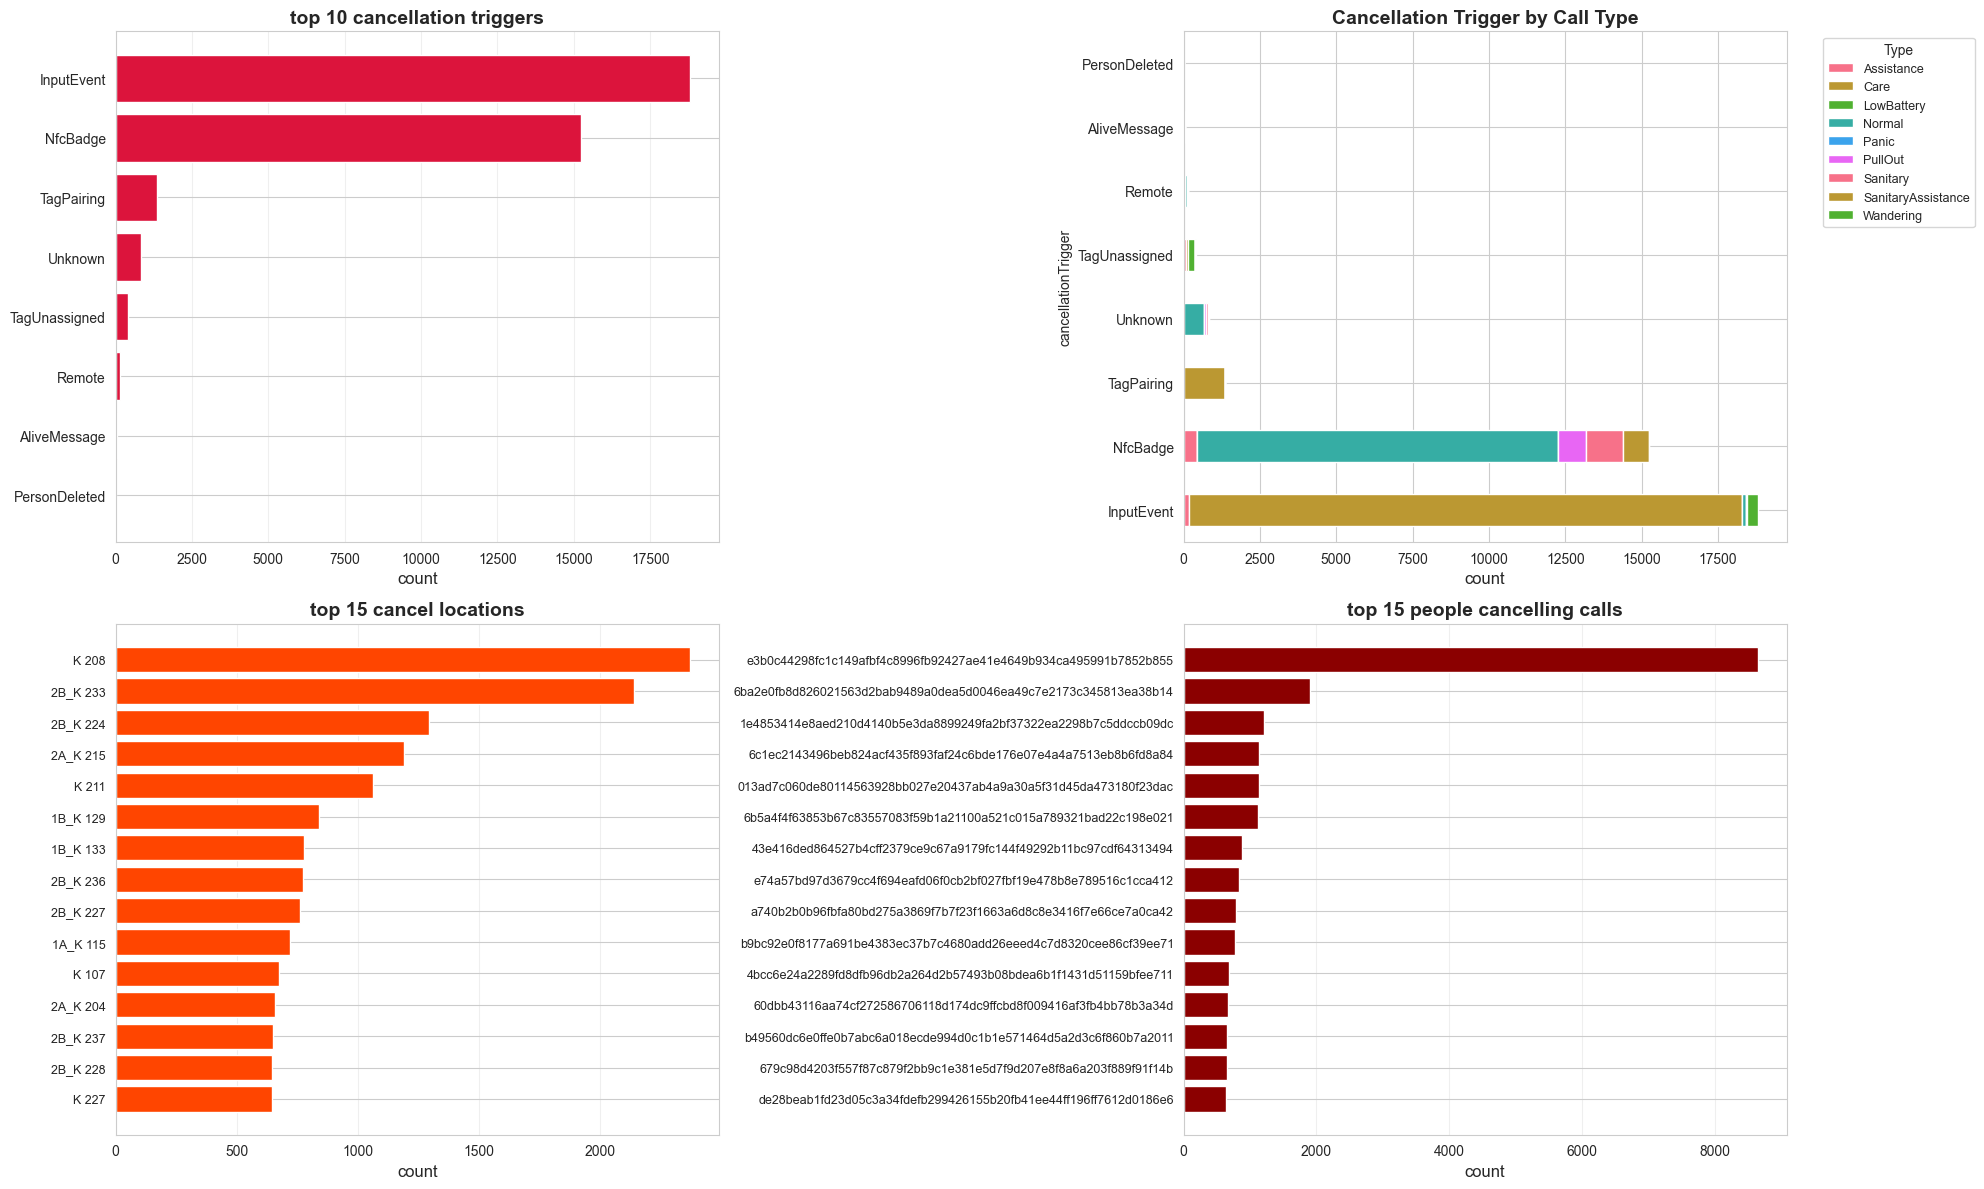


cancellation Insights:
   - most common cancellation trigger: InputEvent (18,806 times)
   - cancelled calls: 15,926 (42.8%)
   - unique cancellation triggers: 8


In [36]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

cancel_trigger_counts = df_historyCall_cleaned['cancellationTrigger'].value_counts().head(10)
axes[0, 0].barh(range(len(cancel_trigger_counts)), cancel_trigger_counts.values, color='crimson')
axes[0, 0].set_yticks(range(len(cancel_trigger_counts)))
axes[0, 0].set_yticklabels(cancel_trigger_counts.index)
axes[0, 0].set_xlabel('count', fontsize=12)
axes[0, 0].set_title('top 10 cancellation triggers', fontsize=14, fontweight='bold')
axes[0, 0].grid(axis='x', alpha=0.3)
axes[0, 0].invert_yaxis()

# cancellation trigger by call type
cancel_type_ct = pd.crosstab(df_historyCall_cleaned['cancellationTrigger'], df_historyCall_cleaned['type'])
top_cancel_triggers = cancel_trigger_counts.head(8).index
cancel_type_filtered = cancel_type_ct.loc[top_cancel_triggers]
cancel_type_filtered.plot(kind='barh', stacked=True, ax=axes[0, 1])
axes[0, 1].set_xlabel('count', fontsize=12)
axes[0, 1].set_title('Cancellation Trigger by Call Type', fontsize=14, fontweight='bold')
axes[0, 1].legend(title='Type', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)

# cancel location distribution
if df_historyCall_cleaned['cancelLocation'].notna().sum() > 0:
    cancel_loc_counts = df_historyCall_cleaned['cancelLocation'].value_counts().head(15)
    axes[1, 0].barh(range(len(cancel_loc_counts)), cancel_loc_counts.values, color='orangered')
    axes[1, 0].set_yticks(range(len(cancel_loc_counts)))
    axes[1, 0].set_yticklabels(cancel_loc_counts.index, fontsize=9)
    axes[1, 0].set_xlabel('count', fontsize=12)
    axes[1, 0].set_title('top 15 cancel locations', fontsize=14, fontweight='bold')
    axes[1, 0].grid(axis='x', alpha=0.3)
    axes[1, 0].invert_yaxis()
else:
    axes[1, 0].text(0.5, 0.5, 'No cancel location data', ha='center', va='center', fontsize=14)
    axes[1, 0].axis('off')

# person who cancelled
if df_historyCall_cleaned['cancelPerson'].notna().sum() > 0:
    cancel_person_counts = df_historyCall_cleaned['cancelPerson'].value_counts().head(15)
    axes[1, 1].barh(range(len(cancel_person_counts)), cancel_person_counts.values, color='darkred')
    axes[1, 1].set_yticks(range(len(cancel_person_counts)))
    axes[1, 1].set_yticklabels(cancel_person_counts.index, fontsize=9)
    axes[1, 1].set_xlabel('count', fontsize=12)
    axes[1, 1].set_title('top 15 people cancelling calls', fontsize=14, fontweight='bold')
    axes[1, 1].grid(axis='x', alpha=0.3)
    axes[1, 1].invert_yaxis()
else:
    axes[1, 1].text(0.5, 0.5, 'No cancel person data', ha='center', va='center', fontsize=14)
    axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print(f"\ncancellation Insights:")
print(f"   - most common cancellation trigger: {cancel_trigger_counts.index[0]} ({cancel_trigger_counts.values[0]:,} times)")
print(f"   - cancelled calls: {df_historyCall_cleaned['cancelTimestamp'].notna().sum():,} ({df_historyCall_cleaned['cancelTimestamp'].notna().sum() / len(df_historyCall_cleaned) * 100:.1f}%)")
print(f"   - unique cancellation triggers: {df_historyCall_cleaned['cancellationTrigger'].nunique()}")

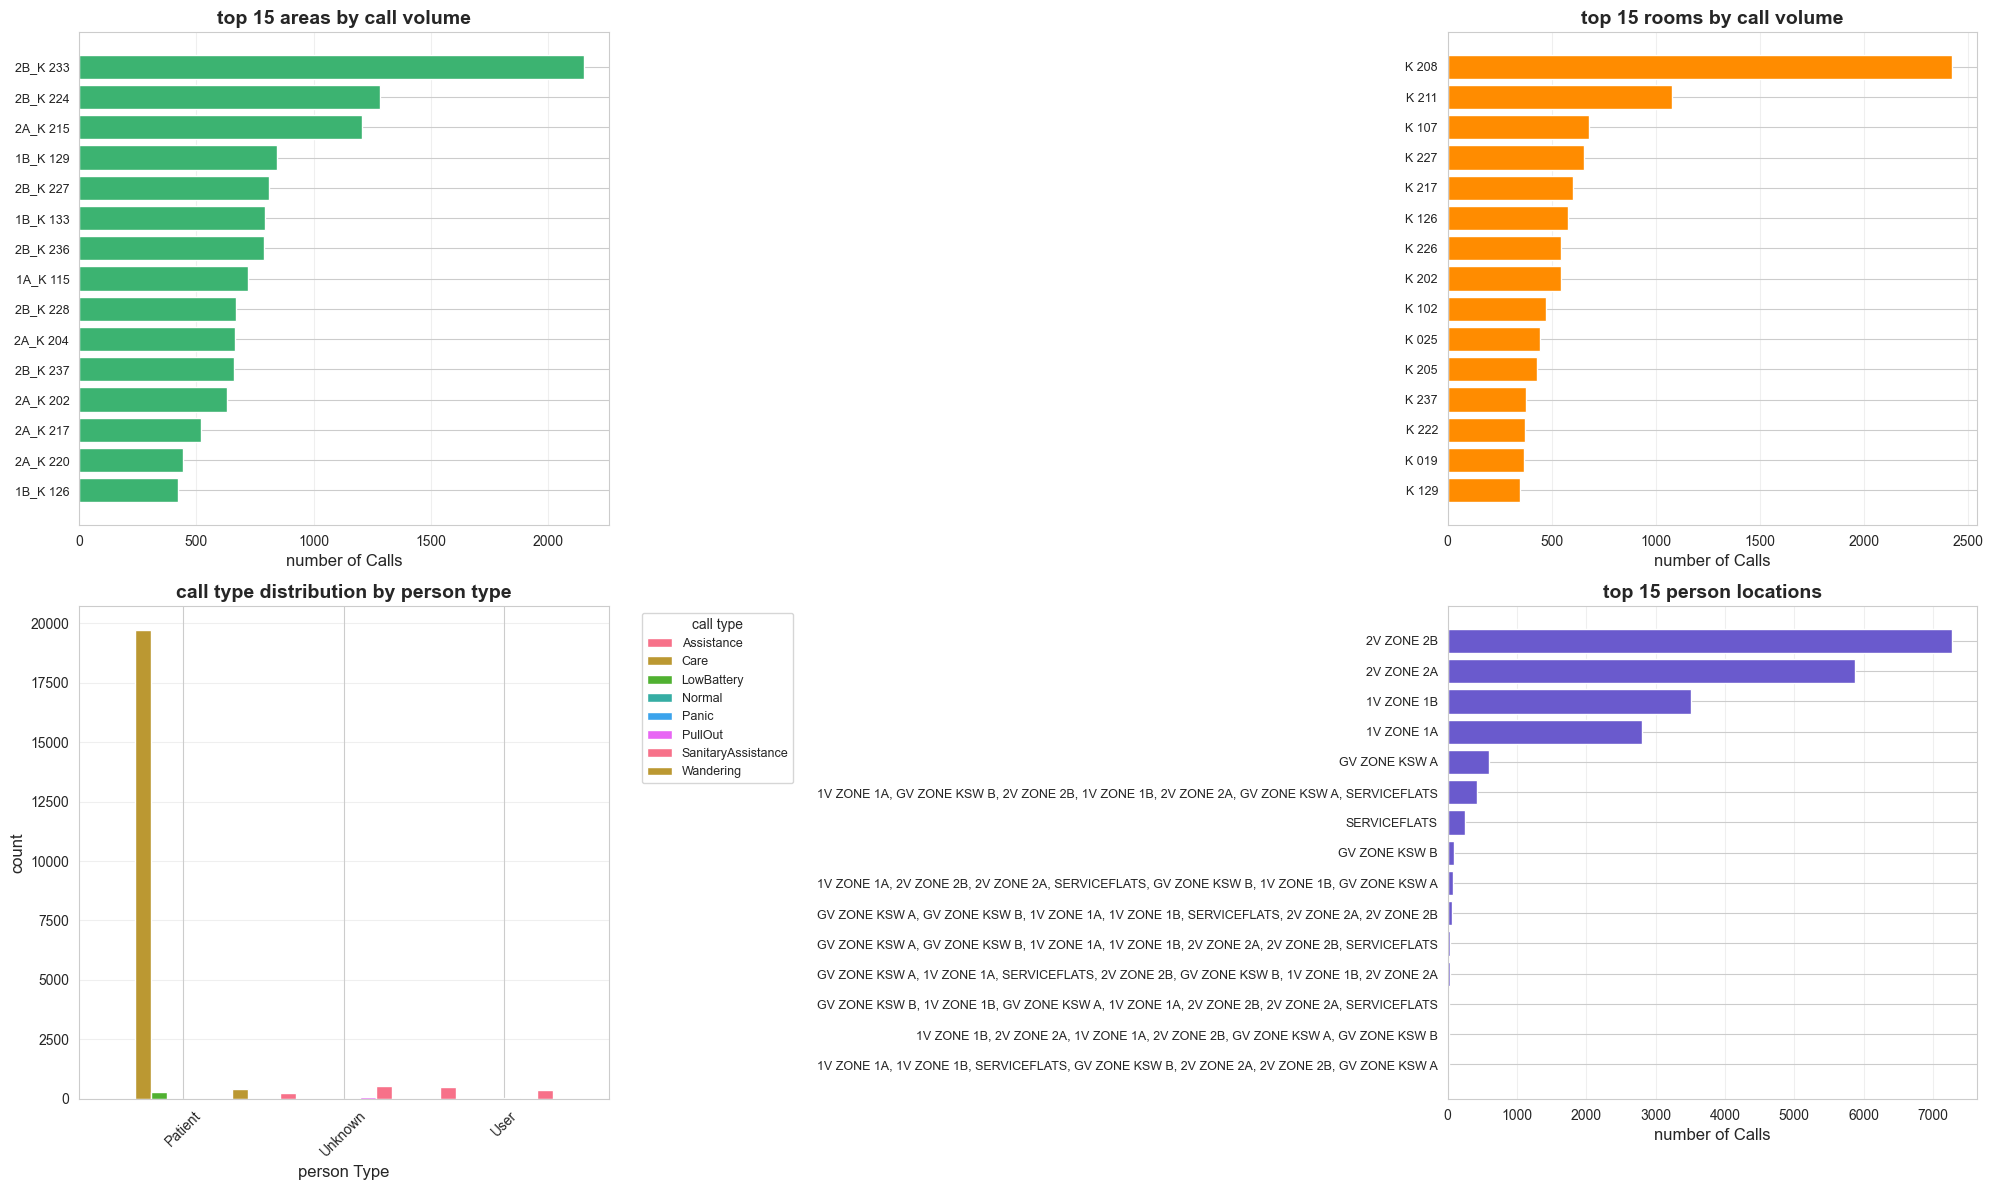


location & person insights:
   - unique areas: 180
   - unique rooms: 183
   - busiest area: 2B_K 233 (2,151 calls)
   - busiest room: K 208 (2,425 calls)

person type distribution:
   - Patient: 20,395 calls (54.8%)
   - User: 920 calls (2.5%)
   - Unknown: 844 calls (2.3%)


In [37]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

# top 15 areas by call volume
area_counts = df_historyCall_cleaned['area'].value_counts().head(15)
axes[0, 0].barh(range(len(area_counts)), area_counts.values, color='mediumseagreen')
axes[0, 0].set_yticks(range(len(area_counts)))
axes[0, 0].set_yticklabels(area_counts.index, fontsize=9)
axes[0, 0].set_xlabel('number of Calls', fontsize=12)
axes[0, 0].set_title('top 15 areas by call volume', fontsize=14, fontweight='bold')
axes[0, 0].grid(axis='x', alpha=0.3)
axes[0, 0].invert_yaxis()

# Top 15 rooms by call volume
room_counts = df_historyCall_cleaned['room'].value_counts().head(15)
axes[0, 1].barh(range(len(room_counts)), room_counts.values, color='darkorange')
axes[0, 1].set_yticks(range(len(room_counts)))
axes[0, 1].set_yticklabels(room_counts.index, fontsize=9)
axes[0, 1].set_xlabel('number of Calls', fontsize=12)
axes[0, 1].set_title('top 15 rooms by call volume', fontsize=14, fontweight='bold')
axes[0, 1].grid(axis='x', alpha=0.3)
axes[0, 1].invert_yaxis()

# Person type vs call type
person_type_ct = pd.crosstab(df_historyCall_cleaned['personType'], df_historyCall_cleaned['type'])
person_type_ct.plot(kind='bar', ax=axes[1, 0], width=0.8)
axes[1, 0].set_xlabel('person Type', fontsize=12)
axes[1, 0].set_ylabel('count', fontsize=12)
axes[1, 0].set_title('call type distribution by person type', fontsize=14, fontweight='bold')
axes[1, 0].legend(title='call type', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(axis='y', alpha=0.3)

# Person location distribution (top 15)
if df_historyCall_cleaned['personLocation'].notna().sum() > 0:
    person_loc_counts = df_historyCall_cleaned['personLocation'].value_counts().head(15)
    axes[1, 1].barh(range(len(person_loc_counts)), person_loc_counts.values, color='slateblue')
    axes[1, 1].set_yticks(range(len(person_loc_counts)))
    axes[1, 1].set_yticklabels(person_loc_counts.index, fontsize=9)
    axes[1, 1].set_xlabel('number of Calls', fontsize=12)
    axes[1, 1].set_title('top 15 person locations', fontsize=14, fontweight='bold')
    axes[1, 1].grid(axis='x', alpha=0.3)
    axes[1, 1].invert_yaxis()
else:
    axes[1, 1].text(0.5, 0.5, 'no person location data', ha='center', va='center', fontsize=14)
    axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print(f"\nlocation & person insights:")
print(f"   - unique areas: {df_historyCall_cleaned['area'].nunique()}")
print(f"   - unique rooms: {df_historyCall_cleaned['room'].nunique()}")
print(f"   - busiest area: {area_counts.index[0]} ({area_counts.values[0]:,} calls)")
print(f"   - busiest room: {room_counts.index[0]} ({room_counts.values[0]:,} calls)")
print(f"\nperson type distribution:")
for ptype, count in df_historyCall_cleaned['personType'].value_counts().items():
    print(f"   - {ptype}: {count:,} calls ({count/len(df_historyCall_cleaned)*100:.1f}%)")

In [38]:
print( "======== DATA SUMMARY REPORT =========")


print("\nOVERALL STATISTICS:")
print(f"   total records: {len(df_historyCall_cleaned):,}")
print(f"   date range: {df_historyCall_cleaned['timestamp'].min()} to {df_historyCall_cleaned['timestamp'].max()}")
print(f"   total days: {(df_historyCall_cleaned['timestamp'].max() - df_historyCall_cleaned['timestamp'].min()).days}")
print(f"   avg calls/day: {len(df_historyCall_cleaned) / (df_historyCall_cleaned['timestamp'].max() - df_historyCall_cleaned['timestamp'].min()).days:.1f}")


print("\nCALL TYPE BREAKDOWN:")
for call_type, count in df_historyCall_cleaned['type'].value_counts().items():
    pct = count / len(df_historyCall_cleaned) * 100
    print(f"   {call_type:20s}: {count:6,} ({pct:5.1f}%)")

print("\nPRIORITY DISTRIBUTION:")
for priority, count in df_historyCall_cleaned['priority'].value_counts().sort_index().items():
    pct = count / len(df_historyCall_cleaned) * 100
    print(f"   Priority {priority}: {count:6,} ({pct:5.1f}%)")

print("\nKEY INSIGHTS:")
print(f"   - unique Wards: {df_historyCall_cleaned['ward'].nunique()}")
print(f"   - unique Areas: {df_historyCall_cleaned['area'].nunique()}")
print(f"   - unique Rooms: {df_historyCall_cleaned['room'].nunique()}")
print(f"   - unique Persons: {df_historyCall_cleaned['personName'].nunique()}")

print("\nDATA QUALITY:")
total_cells = len(df_historyCall_cleaned) * len(df_historyCall_cleaned.columns)
missing_cells = df_historyCall_cleaned.isna().sum().sum()
print(f"   completeness: {(1 - missing_cells/total_cells) * 100:.1f}%")
print(f"   missing Values: {missing_cells:,} / {total_cells:,}")

print("\nTOP PROBLEM AREAS :")
print("   top 5 wards:")
for i, (ward, count) in enumerate(df_historyCall_cleaned['ward'].value_counts().head(5).items(), 1):
    print(f"      {i}. {ward}: {count:,} calls")

print("\n" + "="*80)

======== DATA SUMMARY REPORT =========

OVERALL STATISTICS:
   total records: 37,225
   date range: 2024-01-31 03:49:14+00:00 to 2024-08-26 11:13:40+00:00
   total days: 208
   avg calls/day: 179.0

CALL TYPE BREAKDOWN:
   Care                : 19,718 ( 53.0%)
   Normal              : 12,879 ( 34.6%)
   Sanitary            :  1,291 (  3.5%)
   PullOut             :  1,015 (  2.7%)
   SanitaryAssistance  :    903 (  2.4%)
   Assistance          :    723 (  1.9%)
   Wandering           :    396 (  1.1%)
   LowBattery          :    281 (  0.8%)
   Panic               :     19 (  0.1%)

PRIORITY DISTRIBUTION:
   Priority 0:     74 (  0.2%)
   Priority 1:    281 (  0.8%)
   Priority 3: 34,833 ( 93.6%)
   Priority 4:  1,622 (  4.4%)
   Priority 5:    415 (  1.1%)

KEY INSIGHTS:
   - unique Wards: 10
   - unique Areas: 180
   - unique Rooms: 183
   - unique Persons: 174

DATA QUALITY:
   completeness: 76.6%
   missing Values: 218,025 / 930,625

TOP PROBLEM AREAS :
   top 5 wards:
      1. 2V 

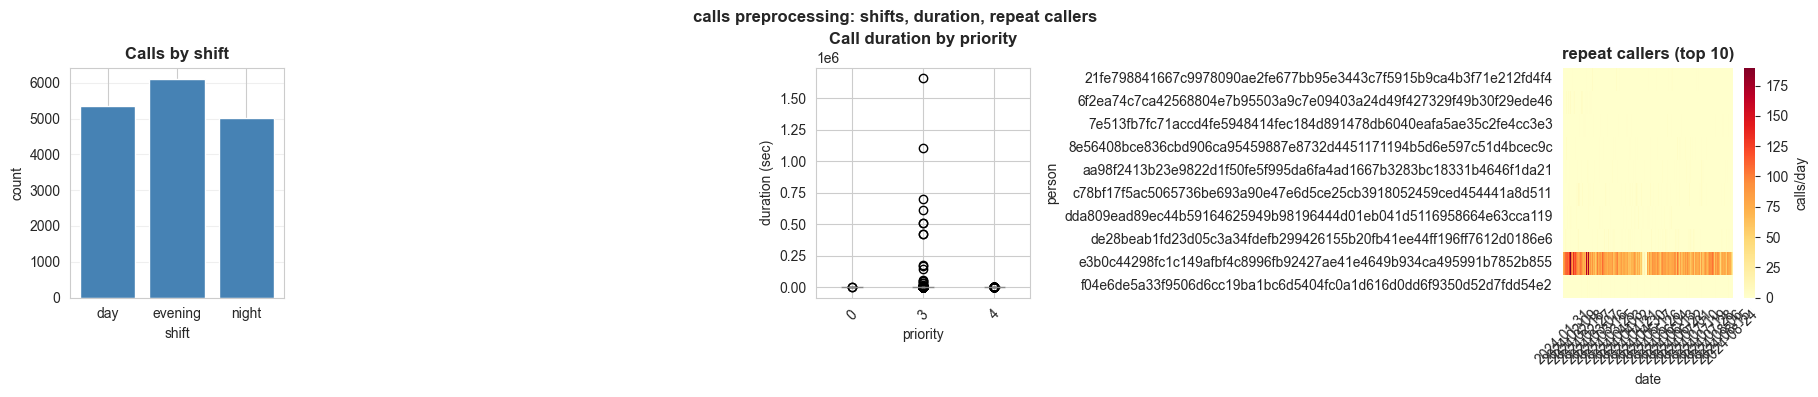

shift counts:
shift
day        5348
evening    6124
night      5029
Name: count, dtype: int64

call duration summary (sec):
count      15926.00
mean         846.89
std        19063.23
min            0.00
25%          100.00
50%          261.00
75%          564.00
max      1658718.00
Name: call_duration_sec, dtype: float64

repeat callers column used: personName


In [39]:
# calls: shift patterns, durations, repeat callers
if "df_historyCall_cleaned" not in globals():
    print("df_historyCall_cleaned not found. Run the calls preprocessing cells first.")
else:
    calls = df_historyCall_cleaned.copy()
    if "timestamp" not in calls.columns:
        print("timestamp column not found in calls data.")
    else:
        calls["timestamp"] = pd.to_datetime(calls["timestamp"], utc=True, errors="coerce")
        calls = calls[calls["timestamp"].notna()].copy()
        calls["date"] = calls["timestamp"].dt.date
        calls["hour"] = calls["timestamp"].dt.hour

        def hour_to_shift(h):
            if 7 <= h <= 14:
                return "day"
            if 15 <= h <= 22:
                return "evening"
            return "night"

        calls["shift"] = calls["hour"].apply(hour_to_shift)

        # duration
        if "cancelTimestamp" in calls.columns:
            calls["cancelTimestamp"] = pd.to_datetime(calls["cancelTimestamp"], utc=True, errors="coerce")
            calls["call_duration_sec"] = (calls["cancelTimestamp"] - calls["timestamp"]).dt.total_seconds()
        else:
            calls["call_duration_sec"] = np.nan

        fig, axes = plt.subplots(1, 3, figsize=(18, 4))

        shift_counts = calls["shift"].value_counts().reindex(["day", "evening", "night"], fill_value=0)
        axes[0].bar(shift_counts.index, shift_counts.values, color="steelblue")
        axes[0].set_title("Calls by shift", fontweight="bold")
        axes[0].set_xlabel("shift")
        axes[0].set_ylabel("count")
        axes[0].grid(axis="y", alpha=0.3)

        duration_data = calls[calls["call_duration_sec"].notna() & (calls["call_duration_sec"] >= 0)].copy()
        if not duration_data.empty:
            group_col = "priority" if "priority" in duration_data.columns else "type"
            duration_data.boxplot(column="call_duration_sec", by=group_col, ax=axes[1], patch_artist=True)
            axes[1].set_title(f"Call duration by {group_col}", fontweight="bold")
            axes[1].set_xlabel(group_col)
            axes[1].set_ylabel("duration (sec)")
            axes[1].tick_params(axis="x", rotation=45)
        else:
            axes[1].text(0.5, 0.5, "No valid duration data", ha="center", va="center")
            axes[1].axis("off")

        person_candidates = ["personName", "personFirstname", "personFirstName", "personId", "person"]
        person_col = next((c for c in person_candidates if c in calls.columns), None)
        if person_col is None:
            axes[2].text(0.5, 0.5, "No person column for repeat callers", ha="center", va="center")
            axes[2].axis("off")
        else:
            calls[person_col] = calls[person_col].astype("string").str.strip()
            per_day = calls.groupby([person_col, "date"]).size().reset_index(name="calls_per_day")
            top_people = (
                per_day.groupby(person_col)["calls_per_day"].sum()
                .sort_values(ascending=False)
                .head(10)
                .index
            )
            top_df = per_day[per_day[person_col].isin(top_people)]
            pivot = top_df.pivot_table(
                index=person_col,
                columns="date",
                values="calls_per_day",
                aggfunc="sum",
                fill_value=0,
            )
            sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": "calls/day"}, ax=axes[2])
            axes[2].set_title("repeat callers (top 10)", fontweight="bold")
            axes[2].set_xlabel("date")
            axes[2].set_ylabel("person")
            axes[2].tick_params(axis="x", rotation=45)

        plt.suptitle("calls preprocessing: shifts, duration, repeat callers", fontweight="bold")
        plt.tight_layout()
        plt.show()

        print("shift counts:")
        print(shift_counts)
        if not duration_data.empty:
            print("\ncall duration summary (sec):")
            print(duration_data["call_duration_sec"].describe().round(2))
        if person_col is not None:
            print(f"\nrepeat callers column used: {person_col}")

In [40]:
# staying_time = cancelTimestamp - timestamp
df_historyCall_cleaned['cancelTimestamp'] = pd.to_datetime(
    df_historyCall_cleaned['cancelTimestamp'], utc=True, errors='coerce'
)
df_historyCall_cleaned['staying_time'] = (
    df_historyCall_cleaned['cancelTimestamp'] - df_historyCall_cleaned['timestamp']
).dt.total_seconds()

df_historyCall_cleaned.head()


,ward,clusterId,type,roomId,cancelPerson,personLocation,zone,clusterName,id,personType,...,room,personName,cancellationTrigger,name,cancelLocation,triggeredBy,hour,dayofweek,date,staying_time
0,2V ZONE 2A,1032.0,Normal,71.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,Bed 2,72733,NaN,...,K 205,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 205,NaN,3.0,2.0,2024-01-31,1136.0
1,2V ZONE 2A,1126.0,Normal,89.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,Bed 2,72734,NaN,...,K 223,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 223,NaN,3.0,2.0,2024-01-31,861.0
2,2V ZONE 2A,no value,Care,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,2V ZONE 2A,ZONE 2A,unknown,72735,Patient,...,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,InputEvent,Draadloze oproep,2A_K 221,NaN,NaN,NaN,NaT,NaN
3,2V ZONE 2A,-1.0,Normal,83.0,b49560dc6e0ffe0b7abc6a018ecde994d0c1b1e571464d...,NaN,NaN,unknown,72736,NaN,...,K 217,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 217,NaN,4.0,2.0,2024-01-31,784.0
4,2V ZONE 2B,no value,Care,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,2V ZONE 2B,ZONE 2B,unknown,72737,Patient,...,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,InputEvent,Draadloze oproep,2B_K 233,NaN,NaN,NaN,NaT,NaN


In [41]:
df_historyCall_cleaned['cancelTimestamp'] = pd.to_datetime(
    df_historyCall_cleaned['cancelTimestamp'], utc=True, errors='coerce'
)
df_historyCall_cleaned['staying_time'] = (
    df_historyCall_cleaned['cancelTimestamp'] - df_historyCall_cleaned['timestamp']
).dt.total_seconds()

all_types = df_historyCall_cleaned['type'].dropna().unique().tolist()
stay_data = df_historyCall_cleaned[df_historyCall_cleaned['staying_time'].notna()].copy()

print("all types in data:", all_types)
print("types with staying_time:", stay_data['type'].unique().tolist())

# calculate how many rows per type, and how many have missing cancelTimestamp
type_counts = df_historyCall_cleaned['type'].value_counts().reindex(all_types).fillna(0)
nat_counts = df_historyCall_cleaned['cancelTimestamp'].isna().groupby(
    df_historyCall_cleaned['type']
).sum().reindex(all_types).fillna(0)

debug = pd.DataFrame({
    'total_rows': type_counts.astype(int),
    'cancelTimestamp_is_NaT': nat_counts.astype(int),
    'has_staying_time': (type_counts - nat_counts).astype(int)
})

print("\ncounts by type:")
print(debug)

all types in data: ['Normal', 'Care', 'Sanitary', 'PullOut', 'Assistance', 'SanitaryAssistance', 'Wandering', 'LowBattery', 'Panic']
types with staying_time: ['Normal', 'Sanitary', 'PullOut', 'Assistance', 'SanitaryAssistance']

counts by type:
                    total_rows  cancelTimestamp_is_NaT  has_staying_time
type                                                                    
Normal                   12879                     518             12361
Care                     19718                   19718                 0
Sanitary                  1291                      47              1244
PullOut                   1015                      40               975
Assistance                 723                     268               455
SanitaryAssistance         903                      12               891
Wandering                  396                     396                 0
LowBattery                 281                     281                 0
Panic                    

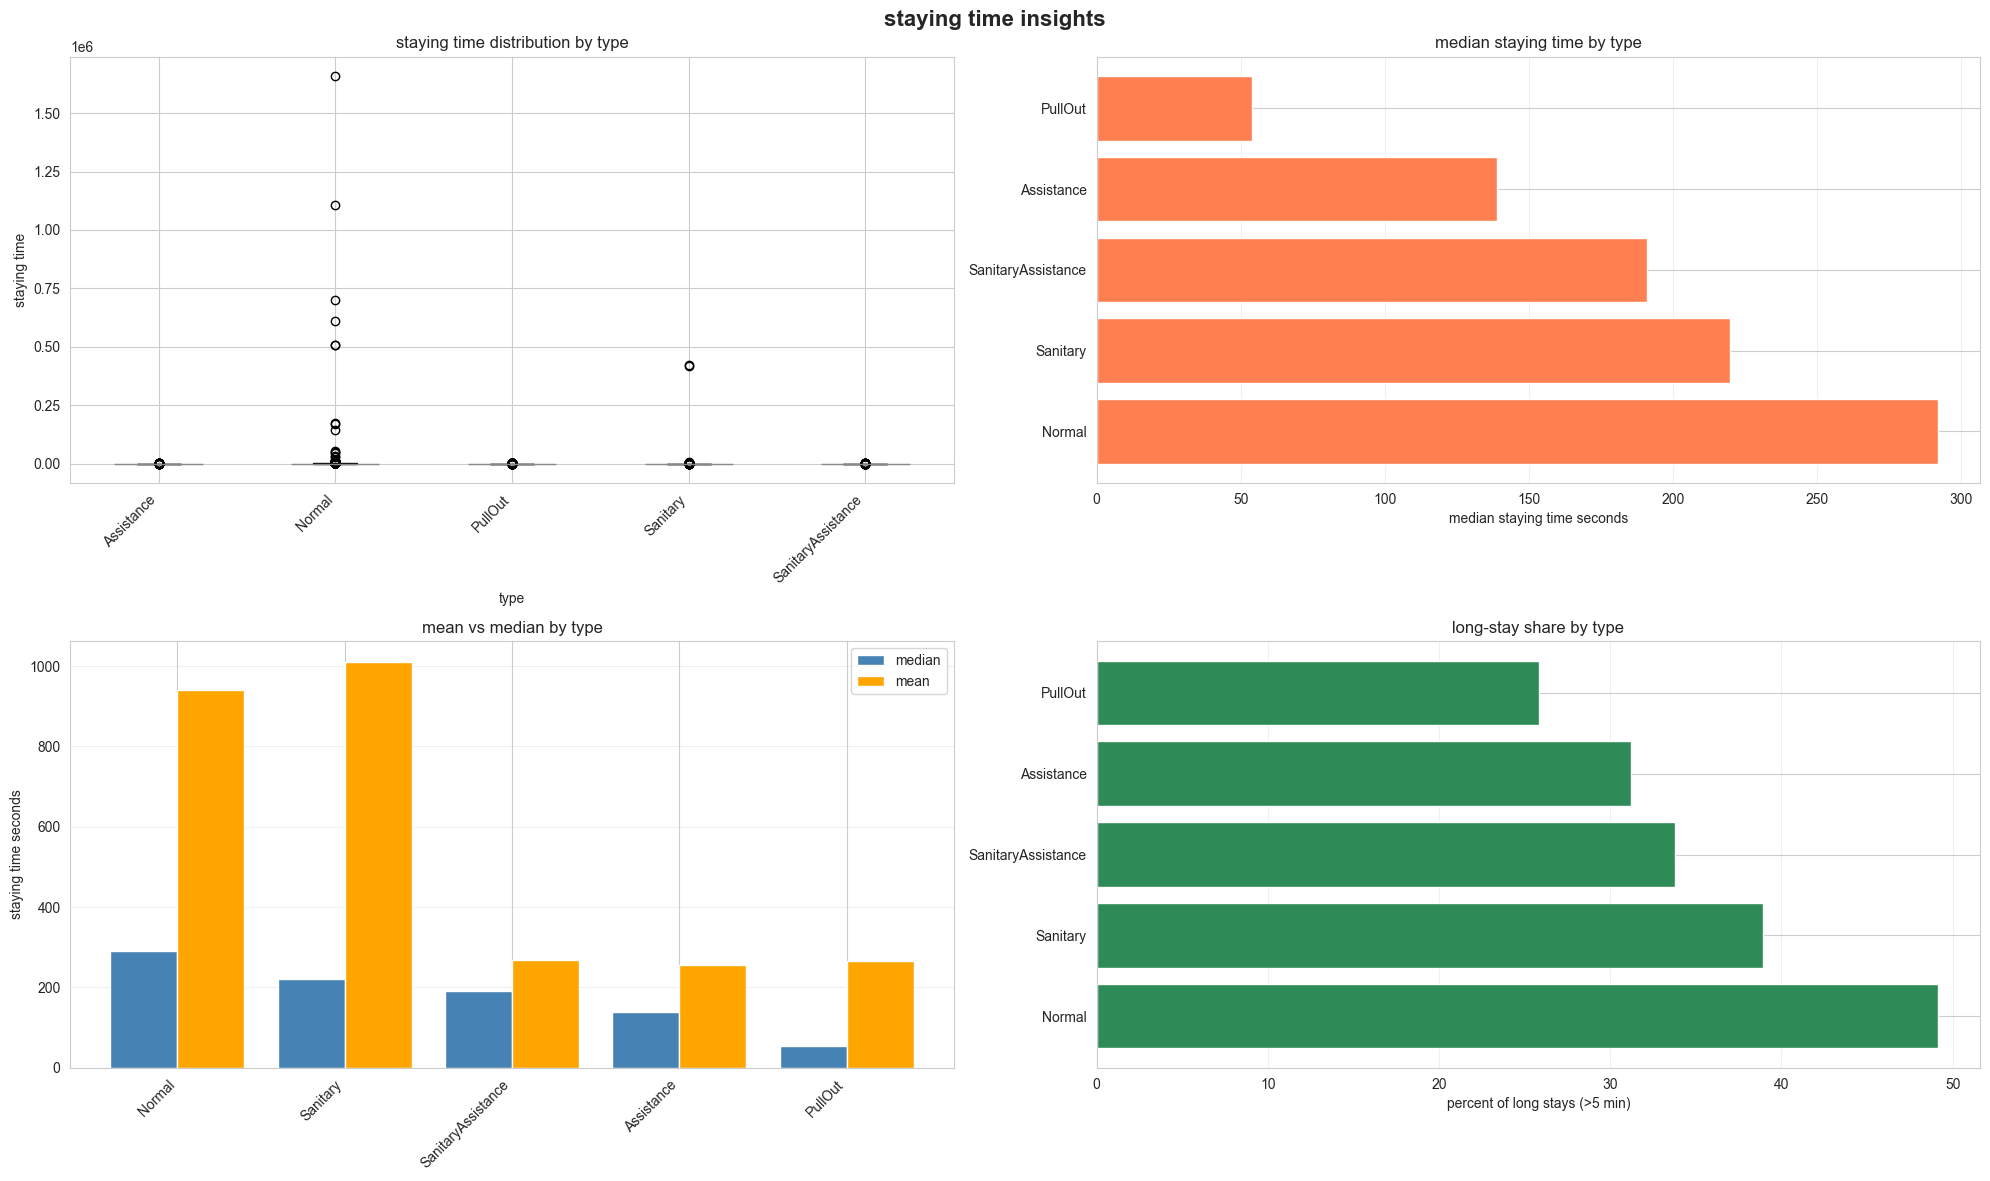

In [42]:
# staying_time plot
df_historyCall_cleaned['cancelTimestamp'] = pd.to_datetime(
    df_historyCall_cleaned['cancelTimestamp'], utc=True, errors='coerce'
)
df_historyCall_cleaned['staying_time'] = (
    df_historyCall_cleaned['cancelTimestamp'] - df_historyCall_cleaned['timestamp']
).dt.total_seconds()

stay_data = df_historyCall_cleaned[df_historyCall_cleaned['staying_time'].notna()].copy()

fig, axes = plt.subplots(2, 2, figsize=(20, 12))

# boxplot by type
all_types = stay_data['type'].value_counts().index
stay_top = stay_data[stay_data['type'].isin(all_types)]
stay_top.boxplot(column='staying_time', by='type', ax=axes[0, 0], patch_artist=True)
axes[0, 0].set_xlabel('type')
axes[0, 0].set_ylabel('staying time')
axes[0, 0].set_title('staying time distribution by type')
plt.sca(axes[0, 0])
plt.xticks(rotation=45, ha='right')

# median staying time
type_stats = stay_data.groupby('type')['staying_time'].median().sort_values(ascending=False)
axes[0, 1].barh(type_stats.index, type_stats.values, color='coral')
axes[0, 1].set_xlabel('median staying time seconds')
axes[0, 1].set_title('median staying time by type')
axes[0, 1].grid(axis='x', alpha=0.3)

# mean vs median by type
type_summary = stay_data.groupby('type')['staying_time'].agg(['mean', 'median']).sort_values('median', ascending=False)
x = np.arange(len(type_summary))
axes[1, 0].bar(x - 0.2, type_summary['median'], width=0.4, label='median', color='steelblue')
axes[1, 0].bar(x + 0.2, type_summary['mean'], width=0.4, label='mean', color='orange')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(type_summary.index, rotation=45, ha='right')
axes[1, 0].set_ylabel('staying time seconds')
axes[1, 0].set_title('mean vs median by type')
axes[1, 0].legend()
axes[1, 0].grid(axis='y', alpha=0.3)

# long stays
threshold = 300
long_share = (
    stay_data.assign(is_long=stay_data['staying_time'] > threshold)
    .groupby('type')['is_long']
    .mean()
    .sort_values(ascending=False)
)
axes[1, 1].barh(long_share.index, long_share.values * 100, color='seagreen')
axes[1, 1].set_xlabel('percent of long stays (>5 min)')
axes[1, 1].set_title('long-stay share by type')
axes[1, 1].grid(axis='x', alpha=0.3)

plt.suptitle('staying time insights', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Preprocessing historyWorkflows.csv

>> Type: 
    - event (fire & forget), eg. Patient left the hospital
    - No additional action is needed after the workflow
    - State eg. Occupied or Care reminder
    - A room can be put in the occupied state and back into unoccupied state.
    - Rounding eg. do a full rounding of the hospital rooms.
    - Presence, simply when a nurse is present in the room 
>> Name:
    - Arbitrary field, can be any string value, configured in the platform.
    - Eg. CareReminder, Occupied, LeftHospital, OutOfBed, InBathroom, ...

In [43]:
df_historyWorkflow = pd.read_csv(historyWorkflows_path, sep=';')
df_historyWorkflow.head()

,timestamp,name,type,id,initiatorPersonName,cancelPersonName,room,cancelTimestamp,activationTime,color,subSystem,ward,scope,state
0,2024-01-31T03:44:05Z,Presence,Presence,283574,451e29e614ad790e1ef2244cf61bbd2d4a1257407ac307...,451e29e614ad790e1ef2244cf61bbd2d4a1257407ac307...,K 220,2024-01-31T03:44:06Z,10000000,#6EB221,NaN,2V ZONE 2A,NaN,NaN
1,2024-01-31T04:02:12Z,Presence,Presence,283578,92fc087f2e0d82427cdb4866c1de2b02bdd484efbda259...,92fc087f2e0d82427cdb4866c1de2b02bdd484efbda259...,ZITRUIMTE GANG203,2024-01-31T04:02:13Z,10000000,#6EB221,NaN,2V ZONE 2B,NaN,NaN
2,2024-01-31T04:06:08Z,Presence,Presence,283580,92fc087f2e0d82427cdb4866c1de2b02bdd484efbda259...,92fc087f2e0d82427cdb4866c1de2b02bdd484efbda259...,K 223,2024-01-31T04:06:09Z,10000000,#6EB221,NaN,2V ZONE 2A,NaN,NaN
3,2024-01-31T04:08:10Z,Presence,Presence,283582,92fc087f2e0d82427cdb4866c1de2b02bdd484efbda259...,92fc087f2e0d82427cdb4866c1de2b02bdd484efbda259...,K 205,2024-01-31T04:08:11Z,10000000,#6EB221,NaN,2V ZONE 2A,NaN,NaN
4,2024-01-31T04:14:09Z,Presence,Presence,283584,92fc087f2e0d82427cdb4866c1de2b02bdd484efbda259...,92fc087f2e0d82427cdb4866c1de2b02bdd484efbda259...,K 025,2024-01-31T04:14:13Z,40000000,#6EB221,NaN,GV ZONE KSW B,NaN,NaN


In [44]:
print("historyWorkflow shape:", df_historyWorkflow.shape)
print("\ncolumns:", df_historyWorkflow.columns.tolist())
print("\ndata types:\n", df_historyWorkflow.dtypes)
print("\nfirst 5 rows:")
print(df_historyWorkflow.head())

# check for NaN values
print("\nnan summary:")
nan_summary = df_historyWorkflow.isna().sum().sort_values(ascending=False)
print(nan_summary[nan_summary > 0])

# convert timestamp columns to datetime
datetime_cols = [col for col in df_historyWorkflow.columns if 'time' in col.lower() or 'date' in col.lower()]
for col in datetime_cols:
    df_historyWorkflow[col] = pd.to_datetime(df_historyWorkflow[col], utc=True, errors='coerce')

print("\nupdated historyWorkflow dtypes")
print(df_historyWorkflow.dtypes)

# drop empty columns
empty_cols = df_historyWorkflow.columns[df_historyWorkflow.isna().all()].tolist()
if empty_cols:
    print(f"\ndropping empty columns: {empty_cols}")
    df_historyWorkflow = df_historyWorkflow.drop(columns=empty_cols)

# basic statistics
print("\nshape after cleaning:", df_historyWorkflow.shape)
print("\nremaining columns:", df_historyWorkflow.columns.tolist())

historyWorkflow shape: (27542, 14)

columns: ['timestamp', 'name', 'type', 'id', 'initiatorPersonName', 'cancelPersonName', 'room', 'cancelTimestamp', 'activationTime', 'color', 'subSystem', 'ward', 'scope', 'state']

data types:
 timestamp              str
name                   str
type                   str
id                     str
initiatorPersonName    str
cancelPersonName       str
room                   str
cancelTimestamp        str
activationTime         str
color                  str
subSystem              str
ward                   str
scope                  str
state                  str
dtype: object

first 5 rows:
              timestamp      name      type      id  \
0  2024-01-31T03:44:05Z  Presence  Presence  283574   
1  2024-01-31T04:02:12Z  Presence  Presence  283578   
2  2024-01-31T04:06:08Z  Presence  Presence  283580   
3  2024-01-31T04:08:10Z  Presence  Presence  283582   
4  2024-01-31T04:14:09Z  Presence  Presence  283584   

                               

C:\Users\S_YZH\AppData\Local\Temp\ipykernel_18944\3746224640.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_historyWorkflow[col] = pd.to_datetime(df_historyWorkflow[col], utc=True, errors='coerce')


In [45]:
# percentage of empty values for each column
empty_percentage = (df_historyWorkflow.isna().sum() / len(df_historyWorkflow) * 100).sort_values(ascending=False)

empty_df = pd.DataFrame({
    'column': empty_percentage.index,
    'empty_count': df_historyWorkflow.isna().sum().loc[empty_percentage.index].values,
    'empty_percentage': empty_percentage.values
})

print("Empty Value Summary:")
print(empty_df.to_string(index=False))

print("\nEmpty percentage by column:")
for col, pct in empty_percentage.items():
    if pct > 0:
        print(f"   {col:20s}: {pct:6.2f}%")

Empty Value Summary:
             column  empty_count  empty_percentage
     activationTime        27539         99.989108
              state        26594         96.557984
              scope        26594         96.557984
    cancelTimestamp         1500          5.446228
          timestamp          947          3.438385
          subSystem          211          0.766103
   cancelPersonName            0          0.000000
initiatorPersonName            0          0.000000
                 id            0          0.000000
               type            0          0.000000
               name            0          0.000000
               room            0          0.000000
              color            0          0.000000
               ward            0          0.000000

Empty percentage by column:
   activationTime      :  99.99%
   state               :  96.56%
   scope               :  96.56%
   cancelTimestamp     :   5.45%
   timestamp           :   3.44%
   subSystem        

In [46]:

room_scope = df_historyWorkflow[df_historyWorkflow['scope'] == 'Room']

print(f"Records with scope='Room': {len(room_scope)}")

print(f"\nUnique 'name' values ({room_scope['name'].nunique()}):")
print(room_scope['name'].value_counts())

print(f"\nUnique 'type' values ({room_scope['type'].nunique()}):")
print(room_scope['type'].value_counts())


Records with scope='Room': 948

Unique 'name' values (1):
name
Occupied    948
Name: count, dtype: int64

Unique 'type' values (1):
type
State    948
Name: count, dtype: int64


In [47]:
# check same person between initiator and canceller
required_cols = ["initiatorPersonName", "cancelPersonName"]
missing_cols = [c for c in required_cols if c not in df_historyWorkflow.columns]

if missing_cols:
    print(f"Missing columns: {missing_cols}")
else:
    tmp = df_historyWorkflow.copy()

    for c in required_cols:
        tmp[c] = tmp[c].astype("string").str.strip()

    # compare only rows where both values exist
    both_present = tmp["initiatorPersonName"].notna() & tmp["cancelPersonName"].notna()
    tmp["same_person"] = both_present & (
        tmp["initiatorPersonName"] == tmp["cancelPersonName"]
    )

    print("rows with both values present:", int(both_present.sum()))
    print("rows where initiator == canceller:", int(tmp["same_person"].sum()))
    print("share among comparable rows: {:.2f}%".format(
        100 * tmp["same_person"].sum() / both_present.sum() if both_present.sum() else 0
    ))



rows with both values present: 27542
rows where initiator == canceller: 26148
share among comparable rows: 94.94%


In [48]:
# compare initiator vs canceller, and summarize NAME + TYPE for both groups
required_cols = ["initiatorPersonName", "cancelPersonName"]
missing_cols = [c for c in required_cols if c not in df_historyWorkflow.columns]

if missing_cols:
    print(f"missing columns: {missing_cols}")
else:
    tmp = df_historyWorkflow.copy()

    for c in required_cols:
        tmp[c] = tmp[c].astype("string").str.strip()

    comparable = tmp["initiatorPersonName"].notna() & tmp["cancelPersonName"].notna()
    tmp["same_person"] = comparable & (tmp["initiatorPersonName"] == tmp["cancelPersonName"])

    same_df = tmp[tmp["same_person"]].copy()
    diff_df = tmp[comparable & ~tmp["same_person"]].copy()

    print("=== PERSON COMPARISON SUMMARY ===")
    print(f"rows total: {len(tmp)}")
    print(f"comparable rows: {int(comparable.sum())}")
    print(f"initiator == canceller: {len(same_df)} ({(len(same_df)/max(comparable.sum(),1))*100:.2f}%)")
    print(f"initiator != canceller: {len(diff_df)} ({(len(diff_df)/max(comparable.sum(),1))*100:.2f}%)")

    for col in ["name", "type"]:
        if col in tmp.columns:
            print(f"\n=== {col.upper()} SUMMARY ===")
            for label, d in [("initiator == canceller", same_df), ("initiator != canceller", diff_df)]:
                non_null = d[col].notna().sum()
                print(f"\n{label}:")
                print(f"  rows: {len(d)}")
                print(f"  {col} not null: {int(non_null)} ({(non_null/max(len(d),1))*100:.2f}%)")
                print(f"  top {col} values:")
                print(d[col].value_counts(dropna=False).head(10))
        else:
            print(f"\ncolumn '{col}' not found, so {col} summary is skipped.")

    if {"name", "type"}.issubset(tmp.columns):
        print("\n=== TOP (name, type) COMBINATIONS WHEN initiator != canceller ===")
        print(
            diff_df.groupby(["name", "type"], dropna=False)
            .size()
            .sort_values(ascending=False)
            .head(15)
        )

=== PERSON COMPARISON SUMMARY ===
rows total: 27542
comparable rows: 27542
initiator == canceller: 26148 (94.94%)
initiator != canceller: 1394 (5.06%)

=== NAME SUMMARY ===

initiator == canceller:
  rows: 26148
  name not null: 26148 (100.00%)
  top name values:
name
Presence    25200
Occupied      948
Name: count, dtype: int64

initiator != canceller:
  rows: 1394
  name not null: 1394 (100.00%)
  top name values:
name
Presence    1394
Name: count, dtype: int64

=== TYPE SUMMARY ===

initiator == canceller:
  rows: 26148
  type not null: 26148 (100.00%)
  top type values:
type
Presence    25200
State         948
Name: count, dtype: int64

initiator != canceller:
  rows: 1394
  type not null: 1394 (100.00%)
  top type values:
type
Presence    1394
Name: count, dtype: int64

=== TOP (name, type) COMBINATIONS WHEN initiator != canceller ===
name      type    
Presence  Presence    1394
dtype: int64


### plots regarding historyWorkflows

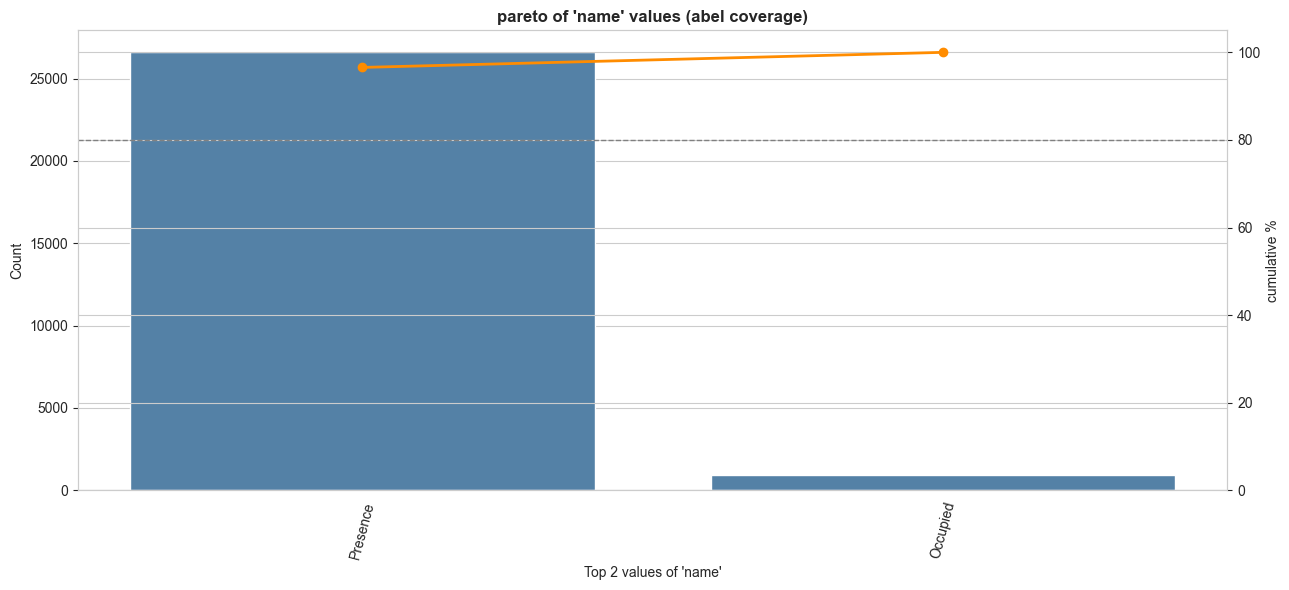

using column: name
distinct labels: 2
labels covering ~80% of rows: 1


In [49]:
candidate_cols = ["name", "type", "state", "scope", "subsystem"]
label_col = next((c for c in candidate_cols if c in df_historyWorkflow.columns), None)

if label_col is None:
    print(f"none of {candidate_cols} found in df_historyWorkflow.")
else:
    labels = (
        df_historyWorkflow[label_col]
        .astype("string")
        .str.strip()
        .fillna("<MISSING>")
        .replace("", "<EMPTY>")
    )

    freq = labels.value_counts()
    pareto = freq.to_frame("count")
    pareto["pct"] = pareto["count"] / pareto["count"].sum() * 100
    pareto["cum_pct"] = pareto["pct"].cumsum()

    top_n = min(30, len(pareto))
    plot_df = pareto.head(top_n).copy()

    fig, ax1 = plt.subplots(figsize=(13, 6))
    sns.barplot(x=plot_df.index, y=plot_df["count"], color="steelblue", ax=ax1)
    ax1.set_ylabel("Count")
    ax1.set_xlabel(f"Top {top_n} values of '{label_col}'")
    ax1.tick_params(axis="x", rotation=75)

    ax2 = ax1.twinx()
    ax2.plot(range(top_n), plot_df["cum_pct"], color="darkorange", marker="o", linewidth=2)
    ax2.set_ylabel("cumulative %")
    ax2.set_ylim(0, 105)
    ax2.axhline(80, linestyle="--", color="gray", linewidth=1)

    plt.title(f"pareto of '{label_col}' values (abel coverage)", fontweight="bold")
    plt.tight_layout()
    plt.show()

    total_labels = len(pareto)
    labels_for_80 = int((pareto["cum_pct"] <= 80).sum() + 1)
    print(f"using column: {label_col}")
    print(f"distinct labels: {total_labels}")
    print(f"labels covering ~80% of rows: {labels_for_80}")

### above plot explian and how it help
this plot shows how imbalanced the workflow name labels are
- blue bars are just raw coumts per label, which presence is very frequent, and occupied is much smaller
- orange line is cumulative coverage, which after label Presence, already cover almost all rows

how it help later with llm
- model can look good by mostly predicting presence, but perform poorly on occulied
- should evaluate per class metrics, not just overall accuracy, and consider class balancing, which are weights, resampling or targeted data collection
since here has only 2 labels here, is a strong binary imbalance case rather than a long multi class tail

C:\Users\S_YZH\AppData\Local\Temp\ipykernel_18944\1314678249.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=overall, x="status", y="count", palette=["#4c78a8", "#f58518"], ax=axes[0])


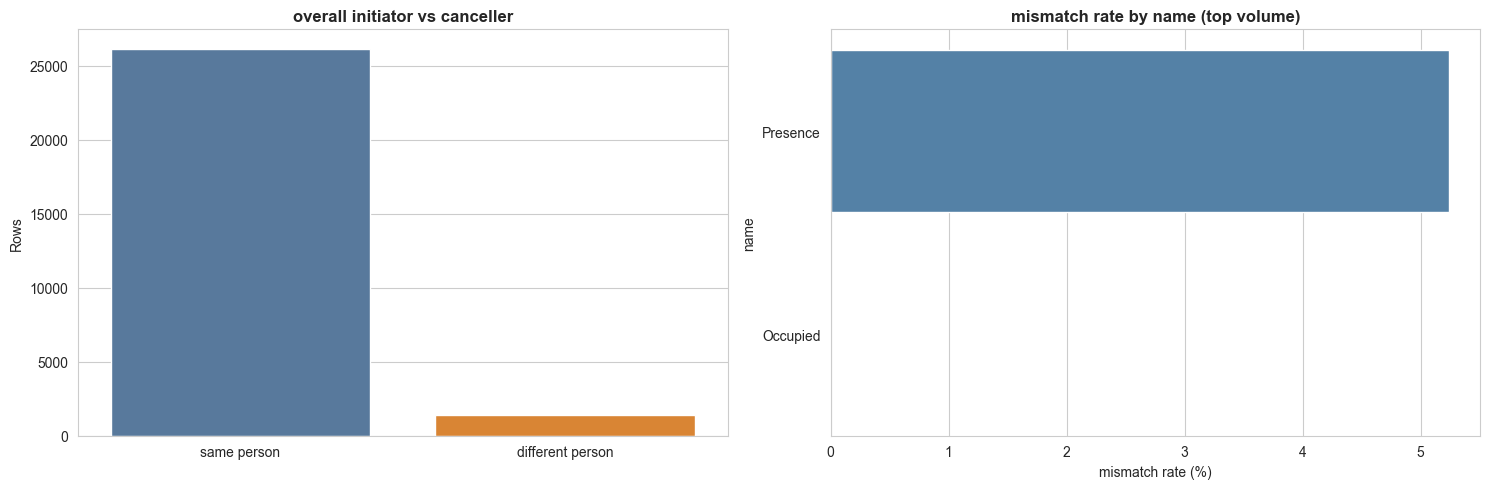

comparable rows: 27542
mismatch rows: 1394 (5.06%)


In [50]:
required_cols = ["initiatorPersonName", "cancelPersonName"]
missing_cols = [c for c in required_cols if c not in df_historyWorkflow.columns]

if missing_cols:
    print(f"missing columns: {missing_cols}")
else:
    tmp = df_historyWorkflow.copy()
    for c in required_cols:
        tmp[c] = tmp[c].astype("string").str.strip()

    comparable = tmp["initiatorPersonName"].notna() & tmp["cancelPersonName"].notna()
    tmp = tmp[comparable].copy()

    if tmp.empty:
        print("no rows where both initiator and canceller are present.")
    else:
        tmp["is_mismatch"] = tmp["initiatorPersonName"] != tmp["cancelPersonName"]

        overall = pd.DataFrame({
            "status": ["same person", "different person"],
            "count": [int((~tmp["is_mismatch"]).sum()), int(tmp["is_mismatch"].sum())]
        })

        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        sns.barplot(data=overall, x="status", y="count", palette=["#4c78a8", "#f58518"], ax=axes[0])
        axes[0].set_title("overall initiator vs canceller", fontweight="bold")
        axes[0].set_xlabel("")
        axes[0].set_ylabel("Rows")

        group_col = "name" if "name" in tmp.columns else ("type" if "type" in tmp.columns else None)
        if group_col is None:
            axes[1].text(0.5, 0.5, "no 'name' or 'type' column for grouped mismatch view", ha="center", va="center")
            axes[1].axis("off")
        else:
            by_group = (
                tmp.groupby(group_col, dropna=False)
                .agg(total=("is_mismatch", "size"), mismatch_rate=("is_mismatch", "mean"))
                .sort_values("total", ascending=False)
                .head(12)
                .reset_index()
            )
            by_group["mismatch_rate_pct"] = by_group["mismatch_rate"] * 100

            sns.barplot(
                data=by_group,
                y=group_col,
                x="mismatch_rate_pct",
                color="steelblue",
                ax=axes[1]
            )
            axes[1].set_title(f"mismatch rate by {group_col} (top volume)", fontweight="bold")
            axes[1].set_xlabel("mismatch rate (%)")
            axes[1].set_ylabel(group_col)

        plt.tight_layout()
        plt.show()

        print(f"comparable rows: {len(tmp)}")
        print(f"mismatch rows: {int(tmp['is_mismatch'].sum())} ({tmp['is_mismatch'].mean()*100:.2f}%)")

### explaination of above plot
- left chart mostly comparable rows are same person, but visible minoriyt are different person
- mismatch rate are 5.06%
- about 1 in 20 workflows are cancelled by sameone other than the same person, its a signal to review

for llm usage
- for later anomaly detection and audit prompts
- prioritize explanations or alerts when missmatch occurs in categories with higher mismatch rate


# Preprocessing historyLocation.CSV

In [51]:
df_historyLocations = pd.read_csv(historyLocations_path, sep=';')
df_historyLocations.head()

,locationUpdateId,deviceId,personId,personFirstName,personLastName,personType,timestamp,altitude,accuracy,clusterId,clusterType,area,areaId,room,roomId,ward,wardId,passage,passageId,zones
0,887287,NaN,329,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,NaN,Patient,2024-01-31T03:36:36.9405602Z,0.0,0.0,NaN,NaN,2A_K 221,175,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': '884342', 'name': 'ZONE 2A'}]"
1,887288,NaN,329,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,NaN,Patient,2024-01-31T03:40:01.3225095Z,0.0,0.0,NaN,NaN,2A_GANG TRAPHAL 202,243,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': '884343', 'name': 'ZONE 2A'}]"
2,887289,NaN,329,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,NaN,Patient,2024-01-31T03:40:22.9954693Z,0.0,0.0,NaN,NaN,2A_K 221,175,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': '884344', 'name': 'ZONE 2A'}]"
3,887290,NaN,266,72a9fdd6c18461162a37f0c8f30aa4fd1afdb9860439ad...,NaN,Patient,2024-01-31T03:41:48.0205314Z,0.0,0.0,NaN,NaN,0A_GANG 002,12,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': '884345', 'name': 'ZONE KSW A'}]"
4,887291,NaN,266,72a9fdd6c18461162a37f0c8f30aa4fd1afdb9860439ad...,NaN,Patient,2024-01-31T03:44:14.9419714Z,0.0,0.0,NaN,NaN,0A_LEEFRUIMTE 002,20,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': '884346', 'name': 'ZONE KSW A'}]"


In [52]:
import ast

# filling empty zone lists with area values as one-item lists
if 'zones' in df_historyLocations.columns and 'area' in df_historyLocations.columns:
    def to_zone_list(value):
        if isinstance(value, list):
            return value

        if pd.isna(value):
            return []

        if isinstance(value, str):
            value = value.strip()

            if value.lower() in ('', 'nan', 'none', 'null', '[]'):
                return []

            # handle stringified lists like "['A', 'B']"
            if value.startswith('[') and value.endswith(']'):
                try:
                    parsed = ast.literal_eval(value)
                    if isinstance(parsed, list):
                        return parsed
                except (ValueError, SyntaxError):
                    pass

            return [value]

        return [str(value)]

    # ensure zones is always a real list
    df_historyLocations['zones'] = df_historyLocations['zones'].apply(to_zone_list)

    empty_zones_mask = df_historyLocations['zones'].apply(lambda z: isinstance(z, list) and len(z) == 0)

    print(f"Rows with empty zones before filling: {empty_zones_mask.sum()}")

    # fill empty zones with area values wrapped as a list
    df_historyLocations.loc[empty_zones_mask, 'zones'] = df_historyLocations.loc[empty_zones_mask, 'area'].apply(
        lambda a: [] if pd.isna(a) or str(a).strip() == '' else [str(a)]
    )

    empty_after = df_historyLocations['zones'].apply(lambda z: isinstance(z, list) and len(z) == 0)
    print(f"Rows with empty zones after filling: {empty_after.sum()}")

    print("\nSample of filled rows:")
    filled_rows = df_historyLocations.loc[empty_zones_mask, ['area', 'zones']].head(5)
    print(filled_rows)
else:
    missing = []
    if 'zones' not in df_historyLocations.columns:
        missing.append('zones')
    if 'area' not in df_historyLocations.columns:
        missing.append('area')
    print(f"Cannot fill zones with area - missing columns: {missing}")

Rows with empty zones before filling: 3044
Rows with empty zones after filling: 0

Sample of filled rows:
                                     area  \
1070  91_Gemeenschappelijke ruimte kelder   
1071  91_Gemeenschappelijke ruimte Kelder   
1084  91_Gemeenschappelijke ruimte Kelder   
1092  91_Gemeenschappelijke ruimte Kelder   
1095  91_Gemeenschappelijke ruimte Kelder   

                                      zones  
1070  [91_Gemeenschappelijke ruimte kelder]  
1071  [91_Gemeenschappelijke ruimte Kelder]  
1084  [91_Gemeenschappelijke ruimte Kelder]  
1092  [91_Gemeenschappelijke ruimte Kelder]  
1095  [91_Gemeenschappelijke ruimte Kelder]  


In [53]:
df_historyLocations.head()
df_historyLocations.info()

<class 'pandas.DataFrame'>
RangeIndex: 579483 entries, 0 to 579482
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   locationUpdateId  579483 non-null  int64  
 1   deviceId          0 non-null       float64
 2   personId          579483 non-null  int64  
 3   personFirstName   579483 non-null  str    
 4   personLastName    0 non-null       float64
 5   personType        579483 non-null  str    
 6   timestamp         579483 non-null  str    
 7   altitude          579483 non-null  float64
 8   accuracy          579483 non-null  float64
 9   clusterId         0 non-null       float64
 10  clusterType       0 non-null       float64
 11  area              579483 non-null  str    
 12  areaId            579483 non-null  int64  
 13  room              0 non-null       float64
 14  roomId            0 non-null       float64
 15  ward              123257 non-null  str    
 16  wardId            123257 non-nu

below convert raw event logs into patient day facts

In [54]:
"""
movement_events: count of location changes per person per day, its 1 for the first record of each person on each day, plus 1 each time location changes from previous record that same day
movement_events = 1 + number_of_location_chages_within_that_person_day
which means when person has location sequence in day like A,A,B,B,C THEN first row count as 1, A->B counts +1, B->C counts +1, total mvoement_events = 3

walk_sessions: for each person, records are split into sessions using time gap rule, which new session if gap > 15 minuts, a session is counted as a walk session only if it has at least one location change which transitions > 0, so that walk_Sessions is the number of those walk sessions per person per day, which this is count of movement sessions, not minuts
example:if a person has 4 sessions in a day and only 2 include location changes, then walk_sessions = 2
"""

if 'df_historyLocations' not in globals():
    print("df_historyLocations is not available.")
else:
    df_loc = df_historyLocations.copy()

    person_candidates = ["personFirstname", "personFirstName", "personName", "personId", "person"]
    time_candidates = ["timestamp", "eventTime", "time", "createdAt", "activationTime", "dateTime"]
    location_candidates = ["zones", "zone", "location", "personLocation", "room", "ward", "area", "subsystem", "scope"]

    person_col = next((c for c in person_candidates if c in df_loc.columns), None)
    time_col = next((c for c in time_candidates if c in df_loc.columns), None)

    available_location_cols = [c for c in location_candidates if c in df_loc.columns]
    if available_location_cols:
        # prefer location column with most within-person/day variation, as that is more likely to capture meaningful movement rather than just being a mostly-static attribute
        location_scores = {}
        for c in available_location_cols:
            tmp_loc = df_loc[[person_col, c]].copy() if person_col in df_loc.columns else df_loc[[c]].copy()
            tmp_loc[c] = tmp_loc[c].astype("string").str.strip()
            location_scores[c] = tmp_loc[c].notna().mean()
        location_col = max(location_scores, key=location_scores.get)
    else:
        location_col = None

    if time_col is None:
        time_like = [c for c in df_loc.columns if "time" in c.lower() or "date" in c.lower()]
        if time_like:
            time_col = time_like[0]

    if person_col is None or time_col is None:
        print("could not find required columns for KPI computation.")
        print(f"detected person column: {person_col}")
        print(f"detected time column: {time_col}")
        print("available columns:")
        print(df_loc.columns.tolist())
    else:
        work = df_loc.copy()
        work[person_col] = work[person_col].astype("string").str.strip()
        work[time_col] = pd.to_datetime(work[time_col], utc=True, errors="coerce")
        work = work[work[person_col].notna() & work[time_col].notna()].copy()

        if work.empty:
            print("no valid rows after filtering person/time.")
        else:
            work = work.sort_values([person_col, time_col]).reset_index(drop=True)
            work["date"] = work[time_col].dt.date

            if location_col is not None:
                work[location_col] = work[location_col].astype("string").str.strip().fillna("<MISSING>")

                # compare locations within each person-day (not across all history)
                work["prev_location"] = work.groupby([person_col, "date"])[location_col].shift(1)
                work["location_changed"] = (
                    (work[location_col] != work["prev_location"]) & work["prev_location"].notna()
                )
                work["transition"] = work["location_changed"].astype(int)
                work["movement_event"] = (
                    work["location_changed"] | work.groupby([person_col, "date"]).cumcount().eq(0)
                ).astype(int)
            else:
                work["transition"] = 0
                work["movement_event"] = 1

            work["gap_min"] = work.groupby(person_col)[time_col].diff().dt.total_seconds().div(60)
            session_gap_min = 15
            work["new_session"] = work["gap_min"].isna() | (work["gap_min"] > session_gap_min)
            work["session_id"] = work.groupby(person_col)["new_session"].cumsum()

            session_stats = (
                work.groupby([person_col, "session_id"], as_index=False)
                .agg(
                    session_start=(time_col, "min"),
                    session_end=(time_col, "max"),
                    points=(time_col, "size"),
                    transitions=("transition", "sum")
                )
            )
            session_stats["session_minutes"] = (
                session_stats["session_end"] - session_stats["session_start"]
            ).dt.total_seconds().div(60).fillna(0)
            session_stats["is_walk_session"] = session_stats["transitions"] > 0
            session_stats["walk_minutes_only"] = np.where(
                session_stats["is_walk_session"],
                session_stats["session_minutes"],
                0.0
            )

            daily_events = (
                work.groupby([person_col, "date"], as_index=False)
                .agg(movement_events=("movement_event", "sum"))
            )

            daily_sessions = (
                session_stats.assign(date=session_stats["session_start"].dt.date)
                .groupby([person_col, "date"], as_index=False)
                .agg(
                    walk_sessions=("is_walk_session", "sum"),
                    walk_minutes=("walk_minutes_only", "sum")
                )
            )

            if location_col is not None:
                daily_locations = (
                    work.groupby([person_col, "date"], as_index=False)
                    .agg(distinct_locations=(location_col, "nunique"), transitions=("transition", "sum"))
                )
            else:
                daily_locations = daily_events.copy()
                daily_locations["distinct_locations"] = np.nan
                daily_locations["transitions"] = 0
                daily_locations = daily_locations[[person_col, "date", "distinct_locations", "transitions"]]

            daily_kpi = (
                daily_events
                .merge(daily_sessions, on=[person_col, "date"], how="left")
                .merge(daily_locations, on=[person_col, "date"], how="left")
                .fillna({"walk_sessions": 0, "walk_minutes": 0, "transitions": 0})
            )

            core_5 = pd.DataFrame([
                {"metric": "1) movement events / person / day (avg)", "value": round(daily_kpi["movement_events"].mean(), 2)},
                {"metric": "2) walk sessions / person / day (avg)", "value": round(daily_kpi["walk_sessions"].mean(), 2)},
                {"metric": "3) walk minutes / person / day (avg)", "value": round(daily_kpi["walk_minutes"].mean(), 2)},
                {"metric": "4) distinct locations / person / day (avg)", "value": round(daily_kpi["distinct_locations"].mean(), 2) if location_col is not None else np.nan},
                {"metric": "5) location transitions / person / day (avg)", "value": round(daily_kpi["transitions"].mean(), 2)}
            ])

            print("columns used:")
            print(f"- person: {person_col}")
            print(f"- timestamp: {time_col}")
            print(f"- location: {location_col if location_col is not None else 'not found'}")
            print(f"- session gap threshold: {session_gap_min} minutes")
            print(f"- valid rows analyzed: {len(work)}")

            print("\n=== CORE 5 info ===")
            display(core_5)

            print("\n=== QUICK DIAGNOSTIC ===")
            print(f"rows with movement_events > 0: {(daily_kpi['movement_events'] > 0).mean() * 100:.2f}%")
            print(f"rows with transitions > 0: {(daily_kpi['transitions'] > 0).mean() * 100:.2f}%")

            print("\n=== TOP 10 PERSON-DAYS BY WALK MINUTES ===")
            display(daily_kpi.sort_values("walk_minutes", ascending=False).head(10))

            print("\n=== DAILY AGGREGATE TREND ===")
            daily_trend = (
                daily_kpi.groupby("date", as_index=False)
                .agg(
                    avg_events=("movement_events", "mean"),
                    avg_sessions=("walk_sessions", "mean"),
                    avg_walk_minutes=("walk_minutes", "mean"),
                    avg_transitions=("transitions", "mean")
                )
                .sort_values("date")
            )
            display(daily_trend.tail(15))

columns used:
- person: personFirstName
- timestamp: timestamp
- location: zones
- session gap threshold: 15 minutes
- valid rows analyzed: 579483

=== CORE 5 info ===


,metric,value
0,1) movement events / person / day (avg),57.88
1,2) walk sessions / person / day (avg),8.45
2,3) walk minutes / person / day (avg),66.66
3,4) distinct locations / person / day (avg),57.71
4,5) location transitions / person / day (avg),56.88



=== QUICK DIAGNOSTIC ===
rows with movement_events > 0: 100.00%
rows with transitions > 0: 99.22%

=== TOP 10 PERSON-DAYS BY WALK MINUTES ===


,personFirstName,date,movement_events,walk_sessions,walk_minutes,distinct_locations,transitions
5906,84ba38f8534bc002a2201907112ee86a554f822254a34e...,2024-06-07,230,28,1123.115341,230,229
5908,84ba38f8534bc002a2201907112ee86a554f822254a34e...,2024-06-09,250,17,854.148886,250,249
5899,84ba38f8534bc002a2201907112ee86a554f822254a34e...,2024-05-31,245,8,698.976037,245,244
2396,37c8bb74056a15104d4c26bbd253b8debc0623aae568cd...,2024-04-23,292,8,651.129753,292,291
3632,5e63888f68a2a136c687c7e2644372a66c27674b838667...,2024-06-27,296,7,646.740081,296,295
5975,9220d657cf4cf34ec7808a157bf522d9ee8173540c5984...,2024-07-11,427,9,609.225027,427,426
2397,37c8bb74056a15104d4c26bbd253b8debc0623aae568cd...,2024-04-24,261,12,583.244112,261,260
5900,84ba38f8534bc002a2201907112ee86a554f822254a34e...,2024-06-01,186,11,579.133819,186,185
9821,fed9c0511b4c44efaa5367eaa423c3400aa64768204c36...,2024-04-23,336,22,569.728821,336,335
2395,37c8bb74056a15104d4c26bbd253b8debc0623aae568cd...,2024-04-22,301,10,563.774153,301,300



=== DAILY AGGREGATE TREND ===


,date,avg_events,avg_sessions,avg_walk_minutes,avg_transitions
191,2024-08-12,75.509091,9.327273,76.342935,74.509091
192,2024-08-13,77.849057,9.415094,91.095234,76.849057
193,2024-08-14,64.333333,9.055556,71.566471,63.333333
194,2024-08-15,55.461538,9.269231,69.125081,54.461538
195,2024-08-16,63.890909,8.345455,74.881774,62.890909
196,2024-08-17,66.215686,8.745098,72.334467,65.215686
197,2024-08-18,60.648148,8.000000,64.919792,59.648148
198,2024-08-19,58.415094,8.528302,65.040910,57.415094
199,2024-08-20,56.641509,8.660377,66.971607,55.641509
200,2024-08-21,71.192308,8.307692,70.221113,70.192308


## Explaination of patient timeline for high activity patient day
- this plot quickly spots behabior patterns like normal routine vs unususal movement bursts
- it also help to validate data quality

this plot can convert into structured features later i will implement, like `num_moves`,ùnique_locations`,`longest_stay`,`peak_movement_hour`, later with llm can generate explainable summary like patient had concentrated movement between 10-11am across 5 locations, it also support anomaly narratives by comparing thisday to baseline days, so the output  are grounded in measurable signals rather than a very vague text


## example template

**template**
- `patient_id`: `<id_or_name>`
- `date`: `<YYYY-MM-DD>`
- `total_records`: `<int>`
- `unique_locations`: `<int>`
- `movement_events`: `<int>`
- `walk_sessions_15min_gap`: `<int>`
- `first_event_time`: `<ISO timestamp>`
- `last_event_time`: `<ISO timestamp>`
- `peak_movement_hour`: `<0-23>`
- `longest_stationary_minutes`: `<float>`
- `top_locations_by_time`: `[{"location":"<loc1>","minutes":<float>}, ...]`
- `anomaly_flags`: `["above_baseline_hourly_movement", "high_location_switching", ...]`
- `data_quality_flags`: `["missing_timestamps", "high_duplicate_points", ...]`

**narrative prompt for LLM**
- `Using only the structured facts below, write a 5-7 sentence clinical/operational summary. Include: (1) movement intensity, (2) time concentration, (3) location spread, (4) comparison to baseline if anomaly_flags exist, (5) one cautious recommendation. Do not infer causes not supported by facts.`

**example output style**
- `On 2026-02-14, patient P-102 had 48 location records across 6 unique locations, with 15 movement events. Activity was concentrated between 09:00 and 12:00, peaking at 10:00. The patient had 4 walk sessions using a 15-minute gap rule. The longest stationary period was 96 minutes in Room A12. Compared with baseline, hourly movement was above expected range in 2 hours. Recommend reviewing care context for the peak window and continuing trend monitoring tomorrow.`


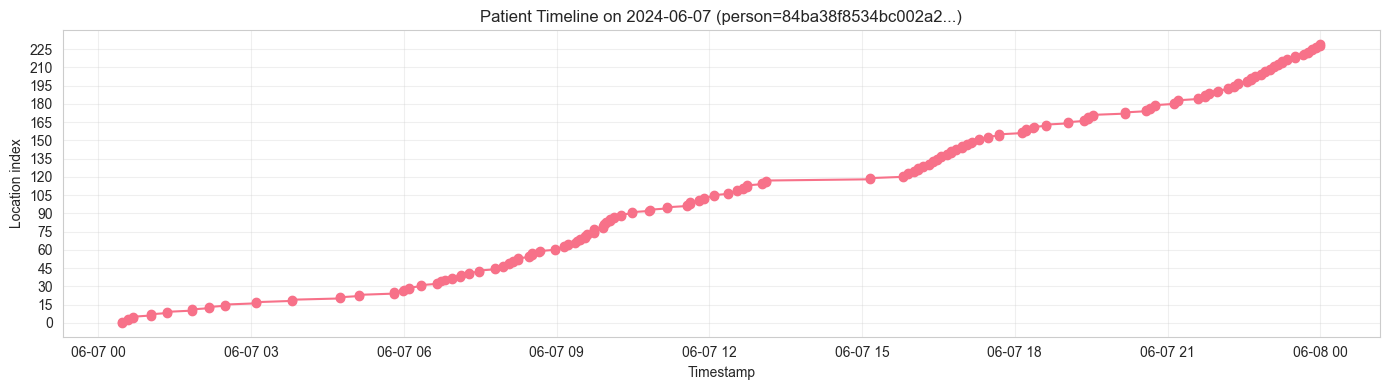

Too many unique locations for full y-labels (230). Showing first 20 location mappings:


,location_index,location
0,0,"[{'id': '319816', 'name': 'SERVICEFLATS 1V'}]"
1,1,"[{'id': '319817', 'name': 'SERVICEFLATS 1V'}]"
2,2,"[{'id': '319820', 'name': 'SERVICEFLATS 1V'}]"
3,3,"[{'id': '319821', 'name': 'SERVICEFLATS 1V'}]"
4,4,"[{'id': '319822', 'name': 'SERVICEFLATS 1V'}]"
5,5,"[{'id': '319823', 'name': 'SERVICEFLATS 1V'}]"
6,6,"[{'id': '319827', 'name': 'SERVICEFLATS 1V'}]"
7,7,"[{'id': '319828', 'name': 'SERVICEFLATS 1V'}]"
8,8,"[{'id': '319834', 'name': 'SERVICEFLATS 1V'}]"
9,9,"[{'id': '319835', 'name': 'SERVICEFLATS 1V'}]"


Selected person: 84ba38f8534bc002a2201907112ee86a554f822254a34e862b3bda2582a0686e
Selected date: 2024-06-07
Records plotted: 230
Unique locations: 230


In [55]:
# patient timeline for a high-activity patient-day
required_vars = ["work", "daily_kpi", "person_col", "time_col", "location_col"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    print(f"Missing required variables: {missing_vars}")
    print("Run the KPI cell first.")
else:
    top_row = daily_kpi.sort_values("walk_minutes", ascending=False).head(1)

    if top_row.empty:
        print("No person-day data found in daily_kpi.")
    else:
        selected_person = top_row.iloc[0][person_col]
        selected_date = top_row.iloc[0]["date"]

        timeline = work[(work[person_col] == selected_person) & (work["date"] == selected_date)].copy()
        timeline = timeline.sort_values(time_col)

        if timeline.empty:
            print("No timeline records found for selected person-day.")
        else:
            timeline["location_str"] = timeline[location_col].astype("string")
            categories = pd.Categorical(timeline["location_str"])
            timeline["location_idx"] = categories.codes

            unique_locs = list(categories.categories)
            n_locs = len(unique_locs)

            plt.figure(figsize=(14, 4))
            plt.plot(timeline[time_col], timeline["location_idx"], marker="o", linewidth=1.5)

            if n_locs <= 25:
                plt.yticks(ticks=range(n_locs), labels=unique_locs)
            else:
                tick_step = max(1, n_locs // 15)
                ticks = list(range(0, n_locs, tick_step))
                plt.yticks(ticks=ticks, labels=ticks)

            plt.title(f"Patient Timeline on {selected_date} (person={str(selected_person)[:18]}...)")
            plt.xlabel("Timestamp")
            plt.ylabel("Location index" if n_locs > 25 else "Location")
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()

            if n_locs > 25:
                mapping_df = pd.DataFrame({"location_index": range(n_locs), "location": unique_locs})
                print(f"Too many unique locations for full y-labels ({n_locs}). Showing first 20 location mappings:")
                display(mapping_df.head(20))

            print(f"Selected person: {selected_person}")
            print(f"Selected date: {selected_date}")
            print(f"Records plotted: {len(timeline)}")
            print(f"Unique locations: {n_locs}")

### Explaination movement time plot with 15 minuts gap sessions and busy period alert
it select a day here i choose most activate day `walk_minuts`, builds a timeline, which filter all location records for that patient on that date, and sort by time, it detect movement which a movement happens when location changes from previous record, also create sessions when a new session starts if the time gap between records is > 15 minutes
first plot shows when movement are concentrated, flat areas whoe inactivity, this makes it easy t see when patient moved the most during the day
second plot show the busy period of the patient, which count movements per hour, calculates mean and standard deviation across hours, flags hours where movement count is > mean + 2 x std as unusually high.


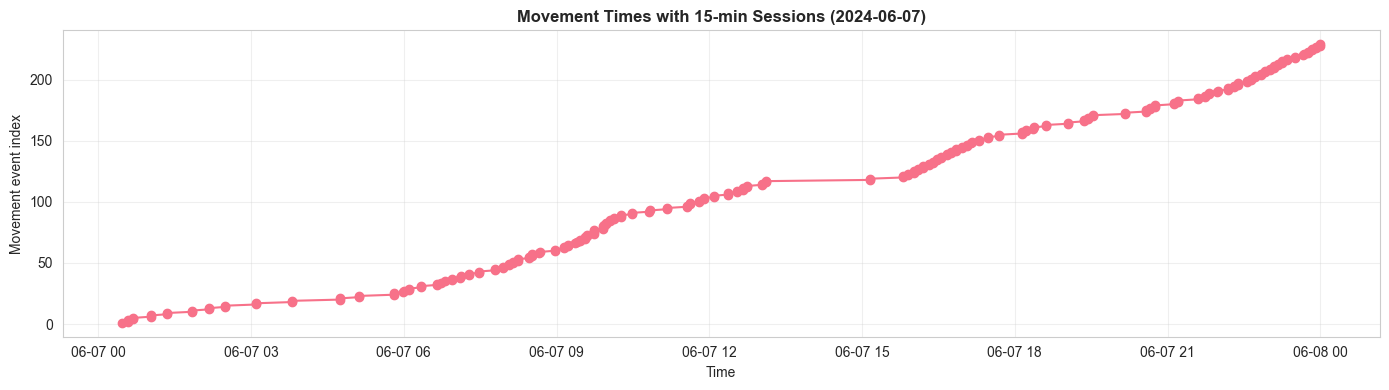

summary: {'person': '84ba38f8534bc002a2201907112ee86a554f822254a34e862b3bda2582a0686e', 'date': '2024-06-07', 'movement_events': 229, 'sessions_total': 28, 'sessions_with_moves': 28, 'first_move_time': '2024-06-07T00:28:25.310731700+00:00', 'last_move_time': '2024-06-07T23:59:47.465660400+00:00', 'session_gap_min': 15}


In [56]:
# movement time plot with 15-min gap sessions and busy-period alert
required_vars = ["work", "daily_kpi", "person_col", "time_col", "location_col"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    print(f"missing required variables: {missing_vars}")
    print("run the KPI cell first.")
else:
    top_row = daily_kpi.sort_values("walk_minutes", ascending=False).head(1)
    if top_row.empty:
        print("no person-day data found in daily_kpi.")
    else:
        selected_person = top_row.iloc[0][person_col]
        selected_date = top_row.iloc[0]["date"]
        timeline = work[(work[person_col] == selected_person) & (work["date"] == selected_date)].copy()
        timeline = timeline.sort_values(time_col)
        if timeline.empty:
            print("no timeline records found for selected person-day.")
        else:
            if location_col is None or location_col not in timeline.columns:
                print("no location column found for movement plot.")
            else:
                timeline[time_col] = pd.to_datetime(timeline[time_col], utc=True, errors="coerce")
                timeline = timeline[timeline[time_col].notna()].copy()
                timeline[location_col] = timeline[location_col].astype("string").str.strip().fillna("<MISSING>")
                timeline["prev_location"] = timeline[location_col].shift(1)
                timeline["moved"] = (timeline[location_col] != timeline["prev_location"]) & timeline["prev_location"].notna()
                timeline["gap_min"] = timeline[time_col].diff().dt.total_seconds().div(60)
                timeline["new_session"] = timeline["gap_min"].isna() | (timeline["gap_min"] > 15)
                timeline["session_id"] = timeline["new_session"].cumsum()
                timeline["movement_event"] = (timeline["moved"] | timeline["new_session"] | timeline.index.to_series().eq(timeline.index.min())).astype(int)

                move_points = timeline[timeline["moved"]].copy()
                if move_points.empty:
                    print("no movement events found for this person-day.")
                else:
                    # Movement time line plot (events over time)
                    plt.figure(figsize=(14, 4))
                    plt.plot(move_points[time_col], range(1, len(move_points) + 1), marker="o", linewidth=1.5)
                    plt.title(f"Movement Times with 15-min Sessions ({selected_date})", fontweight="bold")
                    plt.xlabel("Time")
                    plt.ylabel("Movement event index")
                    plt.grid(alpha=0.3)
                    plt.tight_layout()
                    plt.show()

                    movement_summary = {
                        "person": str(selected_person),
                        "date": str(selected_date),
                        "movement_events": int(len(move_points)),
                        "sessions_total": int(timeline["session_id"].nunique()),
                        "sessions_with_moves": int(move_points["session_id"].nunique()),
                        "first_move_time": move_points[time_col].min().isoformat(),
                        "last_move_time": move_points[time_col].max().isoformat(),
                        "session_gap_min": 15,
                    }
                    print("summary:", movement_summary)

### Explain compare hourly movement against patient's historical baseline
here pick patient and builds a movement event series by hour; and split history into two window which baseline is previous 30 days and compare last 7 days, for each hour it computes a robust baseine using median and MAD then builds a band medium +- 3.5xMAD; it counts movement per hour in compare window and flag hours that exceed the baseline upper band; plot compare line against the baseline median and band, then prints alert hours plus a summary dict.
with median/MAD is resistant to spikes, so baseline isnt distorted by few extreme days, a 30 days baseline coptures routine pattern, a 7 days comapre windw highlights recent deviations
this give LLM an  explainable, stable signal that recent hours eceeded typical range instead of noisy point anomalies

## Explaination of plot below
this plot shows when activity is elevated , its hour level not just simply daily totals, also supports early detection of behabior shift, also produce explainable auditable signals like alert_hours, max_delta_hour...

- this can feed json summary as grounded fact so LLM output are evidence based
- model can also generate concise narrative like recent movement is above baseline at 6-11am strngest at 7am
- it also enables rule based prompting for example escalate only alert_hours count >= threshold and low_variance_band=false.

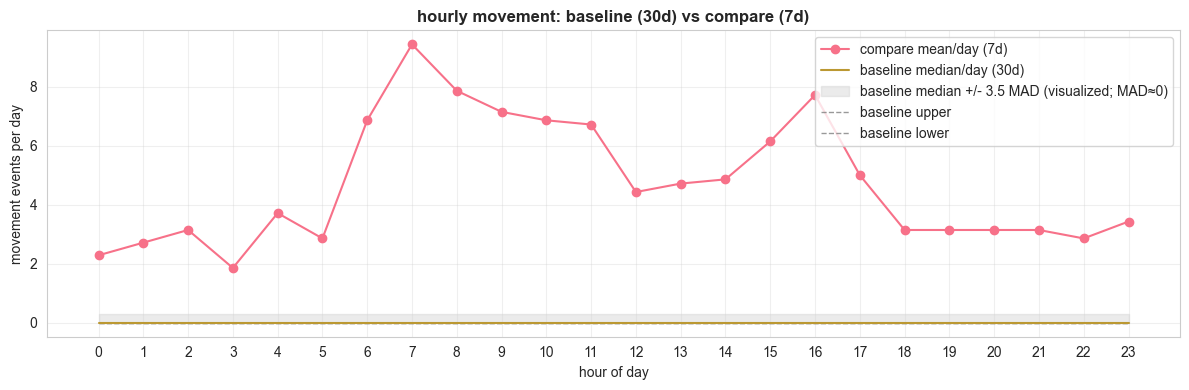

selected person: 84ba38f8534bc002a2201907112ee86a554f822254a34e862b3bda2582a0686e
baseline window: 2024-05-01 to 2024-05-30
compare window: 2024-06-01 to 2024-06-07
baseline MAD near zero, so the plotted band is visually widened only for readability.
alert: above-baseline hours: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
summary_json:
{
  "person": "84ba38f8534bc002a2201907112ee86a554f822254a34e862b3bda2582a0686e",
  "selected_date": "2024-06-07",
  "baseline_window": "2024-05-01 to 2024-05-30",
  "compare_window": "2024-06-01 to 2024-06-07",
  "metric_definition": "compare_mean_per_day_vs_baseline_median_per_day",
  "baseline_days": 30,
  "compare_days": 7,
  "low_variance_band": true,
  "alert_hours": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23
  ],
  "max_delta_hour": 7,
  "max_delta_mean_moves_per_day"

In [ ]:
# compare hourly movement against patient's historical baseline 

# TODO:
# later update code to function for slective dates

import json

required_vars = ["work", "daily_kpi", "person_col", "time_col", "location_col"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    print(f"missing required variables: {missing_vars}")
    print("run the KPI cell first.")
else:
    top_row = daily_kpi.sort_values("walk_minutes", ascending=False).head(1)
    if top_row.empty:
        print("no person-day data found in daily_kpi.")
    else:
        selected_person = top_row.iloc[0][person_col]
        selected_date = pd.Timestamp(top_row.iloc[0]["date"]).normalize()

        hist = work[work[person_col] == selected_person].copy()
        hist[time_col] = pd.to_datetime(hist[time_col], utc=True, errors="coerce")
        hist = hist[hist[time_col].notna()].copy()

        if location_col is None or location_col not in hist.columns:
            print("no location column found for baseline plot.")
        else:
            hist[location_col] = hist[location_col].astype("string").str.strip().fillna("<MISSING>")
            hist = hist.sort_values(time_col)

            hist["date"] = hist[time_col].dt.tz_convert(None).dt.normalize()
            hist["hour"] = hist[time_col].dt.tz_convert(None).dt.hour

            hist["prev_location"] = hist.groupby("date")[location_col].shift(1)
            hist["moved"] = (hist[location_col] != hist["prev_location"]) & hist["prev_location"].notna()
            hist_moves = hist[hist["moved"]].copy()

            baseline_end = selected_date - pd.Timedelta(days=8)
            baseline_start = baseline_end - pd.Timedelta(days=29)
            compare_end = selected_date
            compare_start = selected_date - pd.Timedelta(days=6)

            baseline_dates = pd.date_range(baseline_start, baseline_end, freq="D")
            compare_dates = pd.date_range(compare_start, compare_end, freq="D")

            if len(baseline_dates) == 0 or len(compare_dates) == 0:
                print("invalid baseline/compare date windows.")
            else:
                hourly_counts = (
                    hist_moves.groupby(["date", "hour"]).size().rename("count").reset_index()
                    if not hist_moves.empty
                    else pd.DataFrame(columns=["date", "hour", "count"])
                )

                def build_day_hour_grid(date_index):
                    grid = pd.MultiIndex.from_product([date_index, range(24)], names=["date", "hour"]).to_frame(index=False)
                    out = grid.merge(hourly_counts, on=["date", "hour"], how="left")
                    out["count"] = out["count"].fillna(0).astype(float)
                    return out

                baseline_daily = build_day_hour_grid(baseline_dates)
                compare_daily = build_day_hour_grid(compare_dates)

                baseline_stats = (
                    baseline_daily.groupby("hour")["count"]
                    .agg(median="median")
                    .reindex(range(24), fill_value=0.0)
                )
                tmp = baseline_daily.copy()
                tmp["median"] = tmp.groupby("hour")["count"].transform("median")
                tmp["abs_dev"] = (tmp["count"] - tmp["median"]).abs()
                mad = tmp.groupby("hour")["abs_dev"].median().reindex(range(24), fill_value=0.0)

                baseline_stats["mad"] = mad
                baseline_stats["upper"] = baseline_stats["median"] + 3.5 * baseline_stats["mad"]
                baseline_stats["lower"] = (baseline_stats["median"] - 3.5 * baseline_stats["mad"]).clip(lower=0)

                compare_mean = compare_daily.groupby("hour")["count"].mean().reindex(range(24), fill_value=0.0)
                compare_total = compare_daily.groupby("hour")["count"].sum().reindex(range(24), fill_value=0.0)

                alert_hours = compare_mean[compare_mean > baseline_stats["upper"]].index.tolist()

                plot_lower = baseline_stats["lower"].to_numpy(dtype=float)
                plot_upper = baseline_stats["upper"].to_numpy(dtype=float)
                plot_median = baseline_stats["median"].to_numpy(dtype=float)
                band_width = plot_upper - plot_lower
                low_variance_band = bool(np.allclose(band_width, 0.0))

                if low_variance_band:
                    vis_pad = max(0.10, float(compare_mean.max()) * 0.03)
                    plot_lower_vis = np.clip(plot_lower - vis_pad, a_min=0, a_max=None)
                    plot_upper_vis = plot_upper + vis_pad
                    band_label = "baseline median +/- 3.5 MAD (visualized; MAD≈0)"
                else:
                    plot_lower_vis = plot_lower
                    plot_upper_vis = plot_upper
                    band_label = "baseline median +/- 3.5 MAD"

                plt.figure(figsize=(12, 4))
                plt.plot(range(24), compare_mean.values, marker="o", linewidth=1.5, label="compare mean/day (7d)", zorder=3)
                plt.plot(range(24), plot_median, linewidth=1.5, label="baseline median/day (30d)", zorder=3)
                plt.fill_between(
                    range(24),
                    plot_lower_vis,
                    plot_upper_vis,
                    color="lightgray",
                    alpha=0.45,
                    label=band_label,
                    zorder=1
                )
                plt.plot(range(24), plot_upper, linestyle="--", linewidth=1.0, color="gray", alpha=0.8, label="baseline upper", zorder=2)
                plt.plot(range(24), plot_lower, linestyle="--", linewidth=1.0, color="gray", alpha=0.8, label="baseline lower", zorder=2)
                plt.title("hourly movement: baseline (30d) vs compare (7d)", fontweight="bold")
                plt.xlabel("hour of day")
                plt.ylabel("movement events per day")
                plt.xticks(range(0, 24))
                plt.grid(alpha=0.3)
                plt.legend()
                plt.tight_layout()
                plt.show()

                print(f"selected person: {selected_person}")
                print(f"baseline window: {baseline_start.date()} to {baseline_end.date()}")
                print(f"compare window: {compare_start.date()} to {compare_end.date()}")
                if low_variance_band:
                    print("baseline MAD near zero, so the plotted band is visually widened only for readability.")
                if alert_hours:
                    print(f"alert: above-baseline hours: {alert_hours}")
                else:
                    print("alert: no above-baseline hours detected.")

                delta_mean = compare_mean - baseline_stats["median"]
                max_hour = int(delta_mean.idxmax())

                summary = {
                    "person": str(selected_person),
                    "selected_date": str(selected_date.date()),
                    "baseline_window": f"{baseline_start.date()} to {baseline_end.date()}",
                    "compare_window": f"{compare_start.date()} to {compare_end.date()}",
                    "metric_definition": "compare_mean_per_day_vs_baseline_median_per_day",
                    "baseline_days": int(len(baseline_dates)),
                    "compare_days": int(len(compare_dates)),
                    "low_variance_band": low_variance_band,
                    "alert_hours": [int(h) for h in alert_hours],
                    "max_delta_hour": max_hour,
                    "max_delta_mean_moves_per_day": float(delta_mean.loc[max_hour]),
                    "compare_total_moves": int(compare_total.sum()),
                    "hourly": [
                        {
                            "hour": int(h),
                            "baseline_median": float(baseline_stats.loc[h, "median"]),
                            "baseline_upper": float(baseline_stats.loc[h, "upper"]),
                            "compare_mean": float(compare_mean.loc[h]),
                            "compare_total": int(compare_total.loc[h]),
                            "delta_mean": float(delta_mean.loc[h]),
                            "is_alert": bool(compare_mean.loc[h] > baseline_stats.loc[h, "upper"])
                        }
                        for h in range(24)
                    ]
                }

                print("summary_json:")
                print(json.dumps(summary, indent=2))

---

### EXAMPLE MODEL Integration: Clinical Narrative Generation

**Purpose**: convert the structured JSON summary above into natural language for clinical review.

**what the JSON contains:**
- `alert_hours`: hours where recent activity (7d) significantly exceeded historical baseline (30d)
- `low_variance_band`: Flag indicating if baseline had near-zero variance (very stable routine)
- `hourly[]`: Per-hour breakdown with baseline thresholds, recent averages, and delta

**LLM Benefits:**
1. **summarization**: Condenses 24 hourly metrics + metadata into 5-7 sentences
2. **contextualization**: Explains whether alerts indicate true behavior change or normal variance
3. **clinical framing**: Uses domain-appropriate language ("mobility pattern", "deviation from routine")
4. **actionability**: Provides cautious recommendations like "consider monitoring" vs. "likely normal"
5. **data quality transparency**: Surfaces the `low_variance_band` flag so clinicians know when baseline is unstable

In [67]:
# LLM PROMPT TEMPLATE

llm_system_prompt = """You are a clinical data analyst assistant specializing in patient mobility pattern analysis. 
Your role is to interpret hourly movement deviation summaries and produce concise, cautious narratives for healthcare staff review."""

# summary dict to JSON
summary_json = json.dumps(summary, indent=2)

llm_user_prompt = f"""
**Task**: Summarize the following patient mobility analysis in 5-7 natural language sentences suitable for clinical review.

**Input Data (JSON)**:
```json
{summary_json}
```

**Instructions**:
1. Start with: "Patient [person] on [selected_date]: recent 7-day movement compared to 30-day historical baseline."
2. Mention the metric definition (what "movement" means in this context).
3. If `low_variance_band` is true, explain: "The baseline period showed very stable activity (near-zero variance), so even small changes may trigger alerts."
4. If `alert_hours` is empty, state: "No significant deviations detected. Recent activity within expected bounds."
5. If `alert_hours` is NOT empty:
   - List the alert hours (e.g., "Elevated activity detected at hours 8, 14, 22")
   - Provide magnitude context using `max_delta_mean_moves_per_day` (e.g., "up to +X movements/day on average")
   - Mention the specific hour with maximum deviation (`max_delta_hour`)
6. End with a recommendation:
   - If alert_hours exist AND low_variance_band is false: "Consider reviewing activity logs for hours [X, Y, Z] to determine if intervention is needed."
   - If alert_hours exist AND low_variance_band is true: "Given low baseline variance, these alerts may reflect normal day-to-day variation. Monitor for persistence over multiple weeks."
   - If no alert_hours: "No immediate action recommended. Continue routine monitoring."

**Output Format**: Plain text paragraph (no bullet points, no JSON). Use clinical but accessible language. Be factual and cautious—avoid definitive claims.
"""

print("=" * 80)
print("LLM SYSTEM PROMPT")
print("=" * 80)
print(llm_system_prompt)
print("\n" + "=" * 80)
print("LLM USER PROMPT (preview - first 2000 chars)")
print("=" * 80)
print(llm_user_prompt[:2000] + "\n... [truncated for display] ...")
print("\n" + "=" * 80)
print("USAGE INSTRUCTIONS")
print("=" * 80)
print("1. the full prompt is stored in `llm_user_prompt` variable")
print("2. send both `llm_system_prompt` and `llm_user_prompt` to your LLM API")
print("3. example with OpenAI:")
print("   import openai")
print("   response = openai.ChatCompletion.create(")
print("       model='gpt-4',")
print("       messages=[")
print("           {'role': 'system', 'content': llm_system_prompt},")
print("           {'role': 'user', 'content': llm_user_prompt}")
print("       ]")
print("   )")
print("   narrative = response['choices'][0]['message']['content']")
print("4. The LLM will return a 5-7 sentence clinical narrative")
print("=" * 80)

LLM SYSTEM PROMPT
You are a clinical data analyst assistant specializing in patient mobility pattern analysis. 
Your role is to interpret hourly movement deviation summaries and produce concise, cautious narratives for healthcare staff review.

LLM USER PROMPT (preview - first 2000 chars)

**Task**: Summarize the following patient mobility analysis in 5-7 natural language sentences suitable for clinical review.

**Input Data (JSON)**:
```json
{
  "person": "84ba38f8534bc002a2201907112ee86a554f822254a34e862b3bda2582a0686e",
  "selected_date": "2024-06-07",
  "baseline_window": "2024-05-01 to 2024-05-30",
  "compare_window": "2024-06-01 to 2024-06-07",
  "metric_definition": "compare_mean_per_day_vs_baseline_median_per_day",
  "baseline_days": 30,
  "compare_days": 7,
  "low_variance_band": true,
  "alert_hours": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
 

---

### example LLM Output


> **Patient 84ba38f...0686e on 2024-06-07**: Recent 7-day movement compared to 30-day historical baseline. Movement is defined as location change events per day hour, averaged across the comparison period. The baseline period showed very stable activity (near-zero variance), so even small changes may trigger alerts. Elevated activity detected across all 24 hours, with the maximum deviation at hour 7 (up to +9.4 movements/day on average). The patient had 792 total movement events during the 7-day compare window, substantially higher than the historically stable baseline of near-zero movements per day. Given low baseline variance, these alerts may reflect normal day-to-day variation. Monitor for persistence over multiple weeks.

**key Features**:
- acknowledges the `low_variance_band` flag (explains why alerts are triggered)
- provides magnitude context (+9.4 movements/day at peak hour)
- uses cautious language ("may reflect", "monitor for persistence")
- no definitive clinical recommendations (as requested in the prompt)

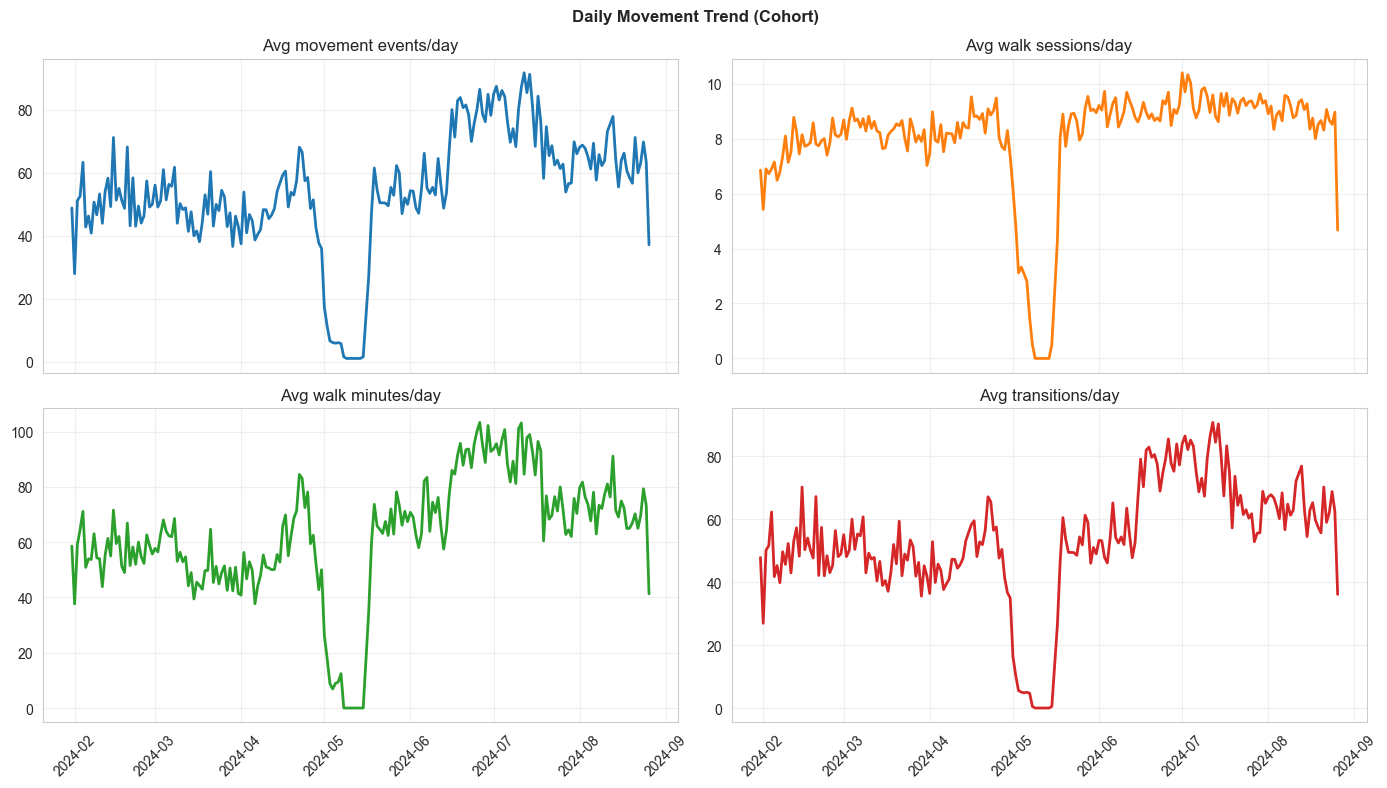

In [ ]:
# trend lines for the four daily movement
if "daily_trend" not in globals():
    print("daily_trend not found. Run the KPI cell first.")
else:
    if daily_trend.empty:
        print("daily_trend is empty.")
    else:
        plot_df = daily_trend.copy().sort_values("date")

        fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

        axes[0, 0].plot(plot_df["date"], plot_df["avg_events"], color="tab:blue", linewidth=2)
        axes[0, 0].set_title("avg movement events/day")
        axes[0, 0].grid(alpha=0.3)

        axes[0, 1].plot(plot_df["date"], plot_df["avg_sessions"], color="tab:orange", linewidth=2)
        axes[0, 1].set_title("avg walk sessions/day")
        axes[0, 1].grid(alpha=0.3)

        axes[1, 0].plot(plot_df["date"], plot_df["avg_walk_minutes"], color="tab:green", linewidth=2)
        axes[1, 0].set_title("avg walk minutes/day")
        axes[1, 0].grid(alpha=0.3)

        axes[1, 1].plot(plot_df["date"], plot_df["avg_transitions"], color="tab:red", linewidth=2)
        axes[1, 1].set_title("avg transitions/day")
        axes[1, 1].grid(alpha=0.3)

        for ax in axes[1, :]:
            ax.tick_params(axis="x", rotation=45)

        plt.suptitle("daily movement trend", fontweight="bold")
        plt.tight_layout()
        plt.show()

---

## Explaination of above plot
good for LLM-generated **executive summaries** and **population reports**.

**1: extract structured trend facts**
```python
trend_summary = {
    "date_range": f"{daily_trend['date'].min()} to {daily_trend['date'].max()}",
    "total_days": len(daily_trend),
    "metrics": {
        "avg_events": {
            "mean": daily_trend["avg_events"].mean(),
            "trend": "increasing" if trend_slope > 0 else "decreasing",
            "volatility": daily_trend["avg_events"].std()
        },
        "avg_sessions": {...},
        "avg_walk_minutes": {...},
        "avg_transitions": {...}
    },
    "anomaly_dates": [list of dates with values >2 std deviations],
    "recent_7day_vs_overall": comparison_dict
}
```

**2. build LLM prompt for executive summary**
```
you are a healthcare operations analyst. summarize the population movement trends for the past 30 days:

- date range: 2024-05-01 to 2024-05-30
- average daily movement events: 95.3 (±12.4)
- average walk sessions: 4.2 (±0.8) 
- average walk minutes: 38.7 (±5.2)
- average transitions: 94.3 (±12.4)
- trend direction: walk_minutes increased 12% over period
- anomaly dates: 2024-05-14 (all metrics -30%, holiday)

write a 5-sentence executive summary including: 
1) overall activity level, 2) trend direction, 3) variability, 
4) notable anomalies, 5) operational recommendation.
```

**3. LLM output example**
> "over the 30-day period from May 1-30, 2024, the patient population maintained stable mobility levels with an average of 95 movement events and 39 walk minutes per patient-day. Walk minutes showed a positive trend, increasing 12% from period start to end, suggesting improved functional capacity or increased therapy engagement. Daily variability was moderate (±12 events, ±5 minutes), indicating predictable operational load. A notable dip occurred on May 14 (all metrics -30%), corresponding to a facility holiday. Recommend continuing current care protocols while investigating May 14 anomaly to confirm it was purely holiday-related rather than a system/staffing issue."

---

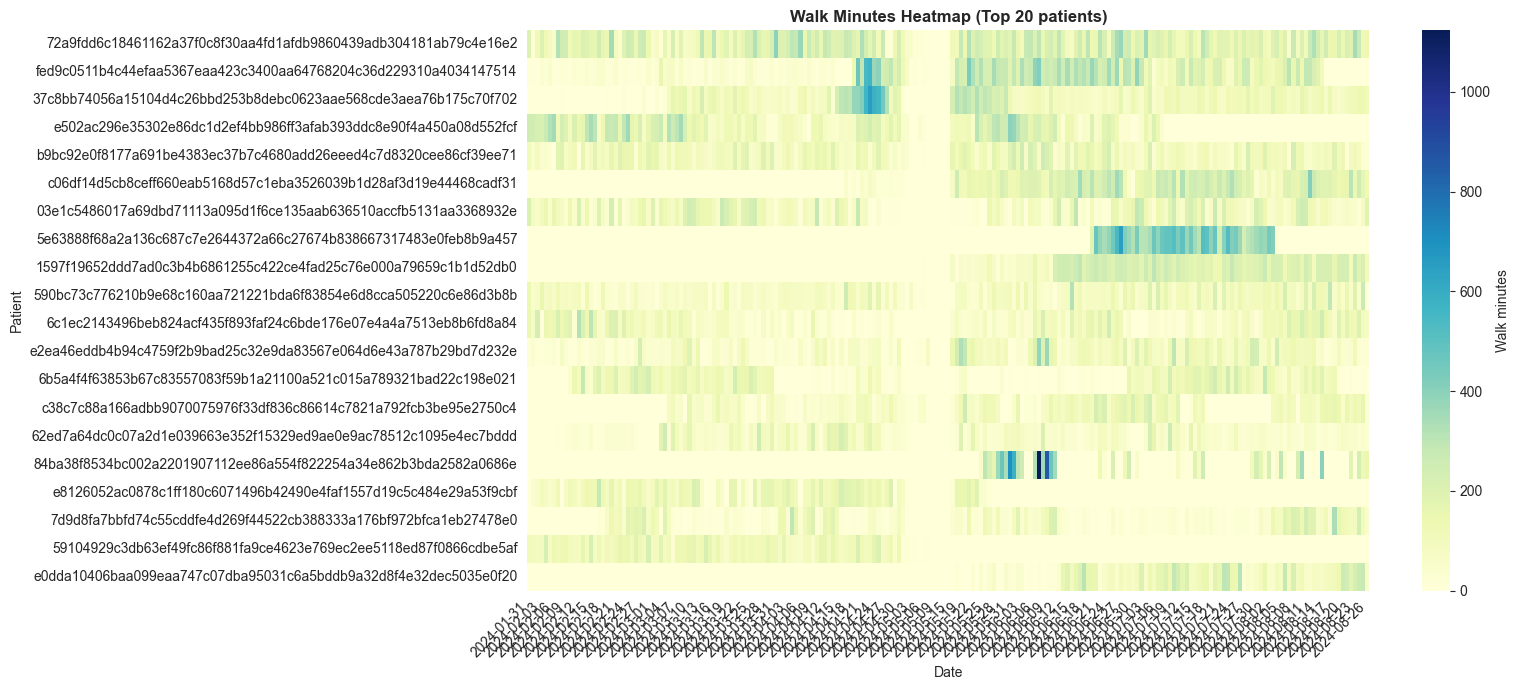

In [72]:
# patient day heatmap of walk minutes 
required_vars = ["daily_kpi", "person_col"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    print(f"Missing required variables: {missing_vars}")
    print("Run the KPI cell first.")
else:
    if daily_kpi.empty:
        print("daily_kpi is empty.")
    else:
        heat_df = daily_kpi.copy()

        top_patients = (
            heat_df.groupby(person_col)["walk_minutes"]
            .sum()
            .sort_values(ascending=False)
            .head(20)
            .index
        )

        heat_df = heat_df[heat_df[person_col].isin(top_patients)].copy()

        pivot_df = heat_df.pivot_table(
            index=person_col,
            columns="date",
            values="walk_minutes",
            aggfunc="sum",
            fill_value=0
        )

        pivot_df = pivot_df.reindex(top_patients)

        plt.figure(figsize=(16, 7))
        sns.heatmap(pivot_df, cmap="YlGnBu", cbar_kws={"label": "Walk minutes"})
        plt.title("Walk Minutes Heatmap (Top 20 patients)", fontweight="bold")
        plt.xlabel("Date")
        plt.ylabel("Patient")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

### Explaination of patient anomaly chart using z-score of daily walk minuts
#### what is measures
for the selected patient, it takes daily `daily walk_minutes`
it also compare each day to that same patient's own baseline (average and variability)
#### Z-score
formula: $z=\frac{x-m}{o}$
x = that day `walk_minuts`
m = patients mean daily deviation of daily walk_minuts
`z=0`: exact around that patiens normal level
`z=+1`: above normal by 1 standard deviation
`z=-1`: below normal by 1 standard deviation
large positive z: unusually high activity day
large negative z: unusually low activity day
#### red lines are at $\pm 2$
the chart flags anomaly if `$|z| \geq 2$`
for unusual values to be more clear to see
points above +2 or -2 are highlighted as anomaly days

#### chart output
"anomalous days = 14" means 14 days were much higher/lower than patient's normal pattern
those days are normally can be some special things
#### how it helpful
give explainable evidence 
support proactive alerts
#### somethings to be note
sensitive to noisy data and missing days
if cariance is tiny, small changes can look large
best used with guardrails, which minimum history window, missing data check, rolling baseline, etc... 




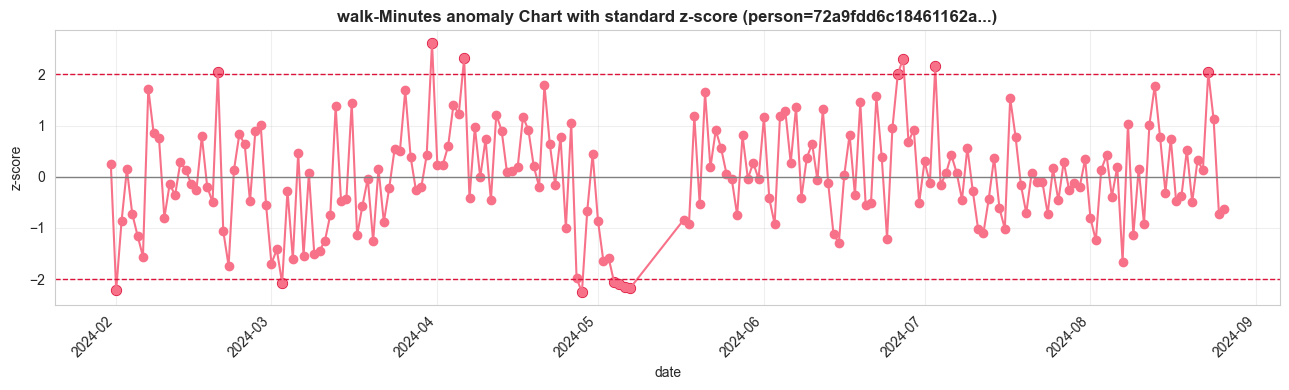

selected person: 72a9fdd6c18461162a37f0c8f30aa4fd1afdb9860439adb304181ab79c4e16e2
anomalous days (|z| >= 2): 14


,date,walk_minutes,zscore_walk_minutes
4974,2024-02-01,8.866192,-2.217187
4993,2024-02-20,349.245698,2.044972
5005,2024-03-03,19.903853,-2.078976
5033,2024-03-31,394.871988,2.616295
5039,2024-04-06,370.799480,2.314864
5061,2024-04-28,5.688819,-2.256973
5067,2024-05-04,22.046600,-2.052145
5068,2024-05-05,19.240374,-2.087284
5069,2024-05-06,13.217427,-2.162702
5070,2024-05-07,12.100405,-2.176689


In [73]:
#patient anomaly chart using z-score of daily walk minutes
required_vars = ["daily_kpi", "person_col"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    print(f"missing required variables: {missing_vars}")
    print("run the KPI cell first.")
else:
    if daily_kpi.empty:
        print("daily_kpi is empty.")
    else:
        selected_person = (
            daily_kpi.groupby(person_col)["walk_minutes"].sum().sort_values(ascending=False).index[0]
        )

        person_daily = daily_kpi[daily_kpi[person_col] == selected_person].copy().sort_values("date")

        if len(person_daily) < 3:
            print("not enough days for anomaly analysis.")
        else:
            mean_val = person_daily["walk_minutes"].mean()
            std_val = person_daily["walk_minutes"].std(ddof=0)

            if std_val == 0:
                person_daily["zscore_walk_minutes"] = 0.0
            else:
                person_daily["zscore_walk_minutes"] = (person_daily["walk_minutes"] - mean_val) / std_val

            person_daily["is_anomaly"] = person_daily["zscore_walk_minutes"].abs() >= 2

            plt.figure(figsize=(13, 4))
            plt.plot(person_daily["date"], person_daily["zscore_walk_minutes"], marker="o", linewidth=1.5)
            plt.axhline(2, linestyle="--", color="crimson", linewidth=1)
            plt.axhline(-2, linestyle="--", color="crimson", linewidth=1)
            plt.axhline(0, linestyle="-", color="gray", linewidth=1)

            anomalies = person_daily[person_daily["is_anomaly"]]
            if not anomalies.empty:
                plt.scatter(anomalies["date"], anomalies["zscore_walk_minutes"], color="crimson", s=50)

            plt.title(f"walk-Minutes anomaly Chart with standard z-score (person={str(selected_person)[:18]}...)", fontweight="bold")
            plt.xlabel("date")
            plt.ylabel("z-score")
            plt.xticks(rotation=45, ha="right")
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()

            print(f"selected person: {selected_person}")
            print(f"anomalous days (|z| >= 2): {int(person_daily['is_anomaly'].sum())}")
            display(person_daily.loc[person_daily["is_anomaly"], ["date", "walk_minutes", "zscore_walk_minutes"]].head(10))

### Explaination of anomaly chart using median and MAD of daily walk minuts
this robust version using median and MAD measures how far a day's `walk_minuts` is from median not mean
scales distance using MEDIAN ABSOLUTE DEVIATION not standard deviation
formula $Z_{robust} = 0.6745 * \frac{x-median}{MAD}$, and flag anomalies when $|Z_{robust}| \geq 3.5 $

#### having this this is better with standard z-score
robust version has less sensitive to outliers, mean and standard deviation can be pulled around by a few extreme days, median and MAD are stable; this one also more reliable with skewed data, which movement data as we know its normally skewed, low days for many then high days for few, so sobust stats fit this senario better; this one also avoid false positives from noisy spikes, which standard z-score can overreact if variability is inflated by a few extreme points; and it works also better with small samples, since this dataset is not as big, median and MAD are more stable baseline

#### standard z-scre are still ok to use is distribution is roughly normal and have a lots of data per person,



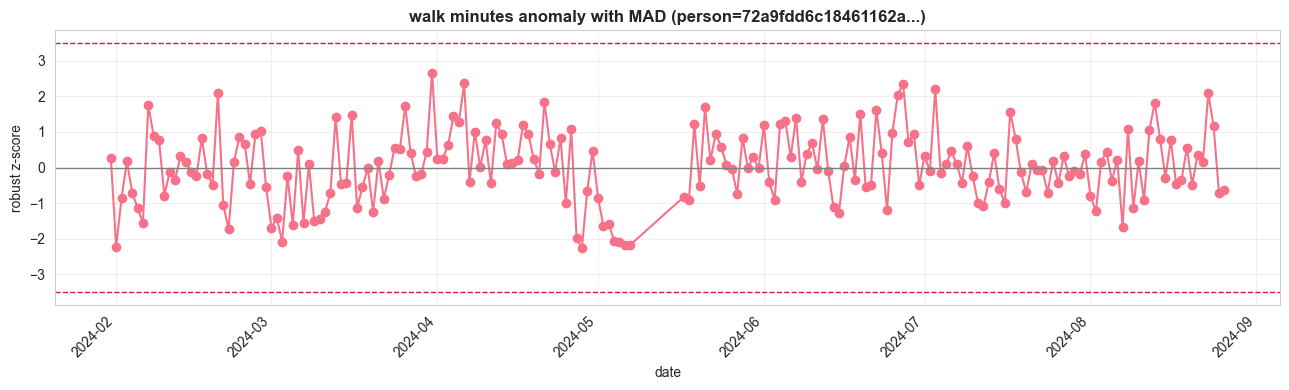

selected person: 72a9fdd6c18461162a37f0c8f30aa4fd1afdb9860439adb304181ab79c4e16e2
anomalous days (|robust z| >= 3.5): 0


,date,walk_minutes,robust_z


In [74]:
# anomaly chart using median and MAD of daily walk minutes
required_vars = ["daily_kpi", "person_col"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    print(f"missing required variables: {missing_vars}")
    print("run the KPI cell first.")
else:
    if daily_kpi.empty:
        print("daily_kpi is empty.")
    else:
        selected_person = (
            daily_kpi.groupby(person_col)["walk_minutes"].sum().sort_values(ascending=False).index[0]
        )

        person_daily = daily_kpi[daily_kpi[person_col] == selected_person].copy().sort_values("date")

        if len(person_daily) < 3:
            print("not enough days for robust anomaly analysis.")
        else:
            median_val = person_daily["walk_minutes"].median()
            mad_val = (person_daily["walk_minutes"] - median_val).abs().median()

            if mad_val == 0:
                person_daily["robust_z"] = 0.0
            else:
                person_daily["robust_z"] = 0.6745 * (person_daily["walk_minutes"] - median_val) / mad_val

            person_daily["is_robust_anomaly"] = person_daily["robust_z"].abs() >= 3.5

            plt.figure(figsize=(13, 4))
            plt.plot(person_daily["date"], person_daily["robust_z"], marker="o", linewidth=1.5)
            plt.axhline(3.5, linestyle="--", color="crimson", linewidth=1)
            plt.axhline(-3.5, linestyle="--", color="crimson", linewidth=1)
            plt.axhline(0, linestyle="-", color="gray", linewidth=1)

            anomalies = person_daily[person_daily["is_robust_anomaly"]]
            if not anomalies.empty:
                plt.scatter(anomalies["date"], anomalies["robust_z"], color="crimson", s=50)

            plt.title(f"walk minutes anomaly with MAD (person={str(selected_person)[:18]}...)", fontweight="bold")
            plt.xlabel("date")
            plt.ylabel("robust z-score")
            plt.xticks(rotation=45, ha="right")
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()

            print(f"selected person: {selected_person}")
            print(f"anomalous days (|robust z| >= 3.5): {int(person_daily['is_robust_anomaly'].sum())}")
            display(person_daily.loc[person_daily["is_robust_anomaly"], ["date", "walk_minutes", "robust_z"]].head(10))


# Facts Layer Data Dictionary

## facts_movement_daily
- person: stable person identifier (name or ID).
- date: UTC day for aggregation (YYYY-MM-DD).
- movement_events: count of movement events per person-day.
- walk_sessions: count of movement sessions per person-day.
- walk_minutes: total minutes in movement sessions per person-day.
- transitions: count of location transitions per person-day.
- distinct_locations: unique locations visited per person-day (nullable).

## facts_movement_hourly
- person: stable person identifier (name or ID).
- date: UTC day for aggregation (YYYY-MM-DD).
- hour: hour of day in 24h format (0-23).
- movement_events: count of movement events in that hour.